# Spotify 오디오 특성 군집화 프로젝트 — test2

이 노트북은 test1의 베이스라인을 보존한 채, 실제 프로젝트용 비교·검증 흐름을 새로 정리합니다.

분석 순서: 데이터 설명 및 EDA → 전처리 → K-Means 베이스라인 → 다른 군집화 비교 및 파라미터 탐색 → 최종 모델 선택 → 통계 검정 및 결과 해석 → 최종 시각화

- 추천용 입력은 오디오 특성입니다. `popularity`, 곡 정보, `explicit`, 장르는 군집화 입력에서 제외합니다.
- `track_genre`는 EDA에서만 확인하고, 사용자가 원한 곡 특성 기반 추천에는 넣지 않습니다.
- 주관적인 청취 평점으로 가중치를 정하는 과정은 사용자 데이터가 생긴 뒤로 미룹니다.
- 수업의 가설검정은 최종 군집을 만든 다음, 군집에 사용하지 않은 popularity와 군집의 관계를 살펴보는 데 적용합니다.

In [197]:
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import kruskal, mannwhitneyu

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, MeanShift, estimate_bandwidth
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score,
    calinski_harabasz_score,
)
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from threadpoolctl import threadpool_limits

import matplotlib.pyplot as plt
plt.rcParams["font.family"] = 'Apple SD Gothic Neo'

RANDOM_STATE = 42

# 노트북을 project2 폴더에서 열거나 저장소 루트에서 열어도 데이터 파일을 찾도록 합니다.
data_candidates = [
    Path("spotify_tracks_dataset/dataset.csv"),
    Path("project2/spotify_tracks_dataset/dataset.csv"),
]
DATA_PATH = next((path for path in data_candidates if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "spotify_tracks_dataset/dataset.csv를 찾지 못했습니다. "
        "project2 폴더 또는 저장소 루트에서 노트북을 실행해 주세요."
    )

df_raw = pd.read_csv(DATA_PATH)
print(f"읽은 파일: {DATA_PATH}")
print(f"원본 크기: {df_raw.shape[0]:,}행 × {df_raw.shape[1]}열")

읽은 파일: spotify_tracks_dataset/dataset.csv
원본 크기: 114,000행 × 21열


## 1. 데이터 설명

각 열의 역할을 먼저 구분합니다. 모델에 넣는 값과 화면 표시·필터·결과 해석에만 쓰는 값은 다릅니다.

In [198]:
column_guide = [
    ("track_id", "곡의 고유 ID", "추천 결과 연결·중복 확인"),
    ("track_name", "곡 제목", "화면 표시"),
    ("artists", "아티스트 이름", "화면 표시"),
    ("album_name", "앨범 이름", "화면 표시"),
    ("popularity", "데이터셋의 인기도 점수(보통 0~100)", "군집화 입력 제외, 외부 결과 검정·해석"),
    ("duration_ms", "곡 길이(밀리초; log1p 변환 버전도 비교)", "오디오 특성 입력"),
    ("explicit", "explicit 콘텐츠 여부", "선택적 화면 필터, 군집화 입력 제외"),
    ("danceability", "춤추기 쉬운 정도 추정치(0~1)", "오디오 특성 입력"),
    ("energy", "곡의 강도·활동성 추정치(0~1)", "오디오 특성 입력"),
    ("key", "곡의 조성 코드(0~11; 실제 분포는 아래에서 확인)", "범주형으로 원-핫 인코딩"),
    ("loudness", "평균 음량(dB)", "오디오 특성 입력"),
    ("mode", "장조(1) / 단조(0)", "범주형으로 원-핫 인코딩"),
    ("speechiness", "말소리 비중 추정치(0~1)", "오디오 특성 입력"),
    ("acousticness", "어쿠스틱한 정도 추정치(0~1)", "오디오 특성 입력"),
    ("instrumentalness", "보컬이 없을 가능성 추정치(0~1)", "오디오 특성 입력"),
    ("liveness", "라이브 공연 녹음일 가능성 추정치(0~1)", "오디오 특성 입력"),
    ("valence", "음악의 긍정적·밝은 정도 추정치(0~1)", "오디오 특성 입력"),
    ("tempo", "템포(BPM)", "오디오 특성 입력"),
    ("time_signature", "박자표(예: 3/4, 4/4를 나타내는 값)", "범주형으로 원-핫 인코딩"),
    ("track_genre", "데이터셋의 세부 장르 라벨", "EDA에서만 확인, 모델 입력 제외"),
    ("Unnamed: 0", "CSV 저장 과정에서 생긴 행 번호", "전처리에서 제거"),
]
display(pd.DataFrame(column_guide, columns=["열", "설명", "프로젝트에서의 역할"]))

,열,설명,프로젝트에서의 역할
0,track_id,곡의 고유 ID,추천 결과 연결·중복 확인
1,track_name,곡 제목,화면 표시
2,artists,아티스트 이름,화면 표시
3,album_name,앨범 이름,화면 표시
4,popularity,데이터셋의 인기도 점수(보통 0~100),"군집화 입력 제외, 외부 결과 검정·해석"
5,duration_ms,곡 길이(밀리초; log1p 변환 버전도 비교),오디오 특성 입력
6,explicit,explicit 콘텐츠 여부,"선택적 화면 필터, 군집화 입력 제외"
7,danceability,춤추기 쉬운 정도 추정치(0~1),오디오 특성 입력
8,energy,곡의 강도·활동성 추정치(0~1),오디오 특성 입력
9,key,곡의 조성 코드(0~11; 실제 분포는 아래에서 확인),범주형으로 원-핫 인코딩


In [199]:
print("데이터 미리보기")
display(df_raw.head())

print("자료형")
display(df_raw.dtypes.rename("dtype").to_frame())

print("결측값 수")
display(df_raw.isna().sum().sort_values(ascending=False).rename("결측 수").to_frame())

print("숫자형 요약 통계")
display(df_raw.select_dtypes(include="number").describe().T)

데이터 미리보기


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


자료형


,dtype
Unnamed: 0,int64
track_id,object
artists,object
album_name,object
track_name,object
popularity,int64
duration_ms,int64
explicit,bool
danceability,float64
energy,float64


결측값 수


,결측 수
artists,1
album_name,1
track_name,1
Unnamed: 0,0
mode,0
time_signature,0
tempo,0
valence,0
liveness,0
instrumentalness,0


숫자형 요약 통계


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,114000.0,56999.500000,32909.109681,0.000,28499.75000,56999.500000,85499.2500,113999.000
popularity,114000.0,33.238535,22.305078,0.000,17.00000,35.000000,50.0000,100.000
duration_ms,114000.0,228029.153114,107297.712645,0.000,174066.00000,212906.000000,261506.0000,5237295.000
danceability,114000.0,0.566800,0.173542,0.000,0.45600,0.580000,0.6950,0.985
energy,114000.0,0.641383,0.251529,0.000,0.47200,0.685000,0.8540,1.000
key,114000.0,5.309140,3.559987,0.000,2.00000,5.000000,8.0000,11.000
loudness,114000.0,-8.258960,5.029337,-49.531,-10.01300,-7.004000,-5.0030,4.532
mode,114000.0,0.637553,0.480709,0.000,0.00000,1.000000,1.0000,1.000
speechiness,114000.0,0.084652,0.105732,0.000,0.03590,0.048900,0.0845,0.965
acousticness,114000.0,0.314910,0.332523,0.000,0.01690,0.169000,0.5980,0.996


## 2. EDA

결측·중복·값의 범위를 살피고, 특히 길이와 오디오 특성의 분포를 확인합니다. 분포가 한쪽으로 치우쳤다는 이유만으로 행을 지우지는 않습니다.

track_id 중복 행 수: 24,259
duration_ms이 0인 행 수: 1
tempo이 0인 행 수: 157
time_signature이 0인 행 수: 163

explicit 비율


,행 수
False,104253
True,9747


,비율(%)
False,91.45
True,8.55


,행 수
조성,
G,13245
C,13061
D,11644
A,11313
C♯/D♭,10772
F,9368
B,9282
E,9008
F♯/G♭,7921


,왜도
duration_ms,11.195181
danceability,-0.399497
energy,-0.597001
loudness,-2.006542
speechiness,4.647516
acousticness,0.727295
instrumentalness,1.734406
liveness,2.105738
valence,0.115078
tempo,0.232295


/var/folders/4v/tf2tg78s6yd4n5__j_8dggcm0000gn/T/ipykernel_54838/3303259062.py:36: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  plt.tight_layout()
/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


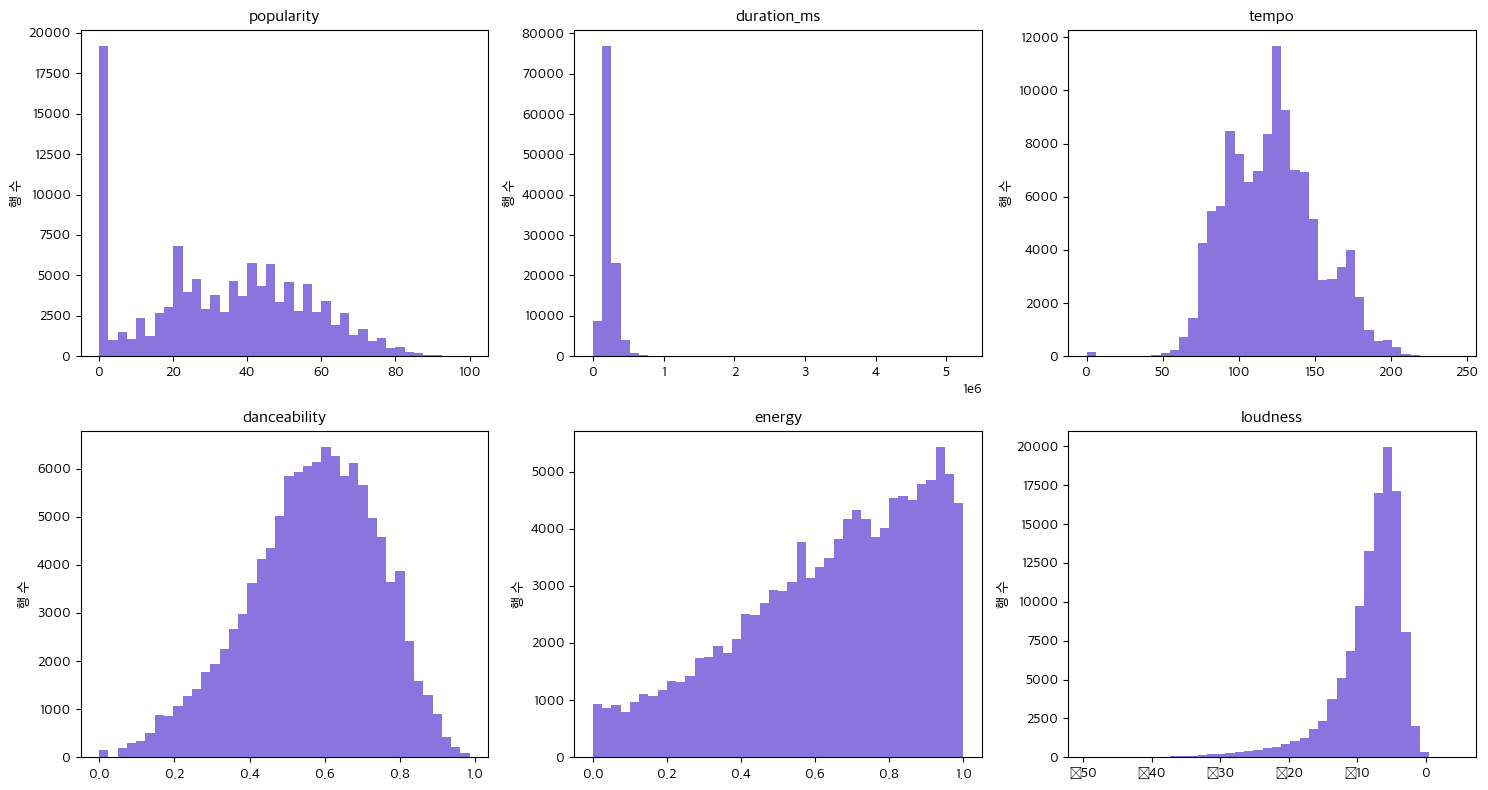

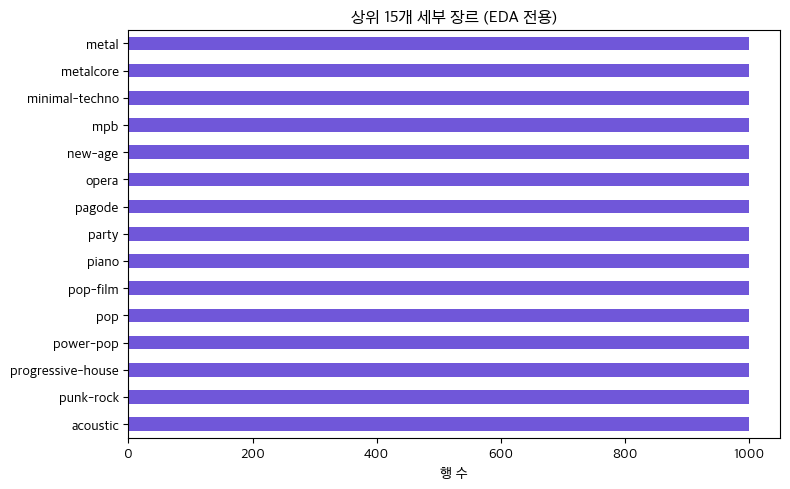

In [200]:
print(f"track_id 중복 행 수: {df_raw['track_id'].duplicated().sum():,}")
for column in ["duration_ms", "tempo", "time_signature"]:
    if column in df_raw.columns:
        print(f"{column}이 0인 행 수: {(df_raw[column] == 0).sum():,}")

if "explicit" in df_raw.columns:
    print("\nexplicit 비율")
    display(df_raw["explicit"].value_counts(dropna=False).to_frame("행 수"))
    display((df_raw["explicit"].value_counts(normalize=True, dropna=False) * 100)
            .round(2).rename("비율(%)").to_frame())

key_names = {-1: "미상", 0: "C", 1: "C♯/D♭", 2: "D", 3: "D♯/E♭",
             4: "E", 5: "F", 6: "F♯/G♭", 7: "G", 8: "G♯/A♭",
             9: "A", 10: "A♯/B♭", 11: "B"}
if "key" in df_raw.columns:
    key_counts = df_raw["key"].map(key_names).fillna("기타/결측")
    display(key_counts.value_counts(dropna=False).rename_axis("조성").to_frame("행 수"))

audio_numeric = [
    "duration_ms", "danceability", "energy", "loudness", "speechiness",
    "acousticness", "instrumentalness", "liveness", "valence", "tempo",
]
available_audio = [c for c in audio_numeric if c in df_raw.columns]
display(df_raw[available_audio].skew(numeric_only=True).rename("왜도").to_frame())

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
plot_columns = ["popularity", "duration_ms", "tempo", "danceability",
                "energy", "loudness"]
for ax, column in zip(axes.flat, plot_columns):
    if column in df_raw.columns:
        ax.hist(df_raw[column].dropna(), bins=40, color="#7057d9", alpha=0.82)
        ax.set_title(column)
        ax.set_ylabel("행 수")
    else:
        ax.set_visible(False)
plt.tight_layout()
plt.show()

if "track_genre" in df_raw.columns:
    genre_top = df_raw["track_genre"].value_counts().head(15).sort_values()
    ax = genre_top.plot(kind="barh", figsize=(8, 5), color="#7057d9")
    ax.set_title("상위 15개 세부 장르 (EDA 전용)")
    ax.set_xlabel("행 수")
    plt.tight_layout()
    plt.show()

## 3. 전처리와 특성 구성

0인 duration은 제거합니다. 중복 track_id는 대표 행 하나만 남기고, popularity 값은 중복 행들의 평균으로 대체합니다. 나머지 컬럼은 기존 방식대로 대표 행의 값을 유지합니다. tempo 또는 time_signature가 0이면 유효한 오디오 특성으로 보기 어려워 분석 대상에서 제외합니다.

연속형 특성은 StandardScaler로 표준화하고, key·mode·time_signature는 범주형으로 원-핫 인코딩합니다. 곡 길이는 원본과 log1p 변환본을 간단한 군집 품질 지표로 비교한 뒤 선택합니다. popularity와 화면 표시용 텍스트는 모델 입력에서 제외합니다.

In [ ]:
continuous_cols = [
    "duration_ms", "danceability", "energy", "loudness", "speechiness",
    "acousticness", "instrumentalness", "liveness", "valence", "tempo",
]
required_cols = continuous_cols + [
    "track_id", "popularity", "key", "mode", "time_signature",
]
missing_columns = [c for c in required_cols if c not in df_raw.columns]
if missing_columns:
    raise KeyError(f"필요한 열이 없습니다: {missing_columns}")

df = df_raw.drop(columns=["Unnamed: 0"], errors="ignore").copy()

numeric_needed = continuous_cols + ["popularity", "key", "mode", "time_signature"]
df[numeric_needed] = df[numeric_needed].apply(pd.to_numeric, errors="coerce")

before = len(df)
df = df.dropna(subset=required_cols).copy()
after_missing = len(df)

df = df[df["duration_ms"] > 0].copy()
after_duration = len(df)

duplicate_track_ids = df.loc[
    df["track_id"].duplicated(keep=False), "track_id"
].nunique()
popularity_mean_by_track = df.groupby("track_id")["popularity"].mean()
# 기존 군집 결과를 재현할 수 있도록 대표 행 선택·정렬은 유지하고, popularity만 아래 평균으로 교체합니다.
df = (
    df.sort_values("popularity", ascending=False, na_position="last")
      .drop_duplicates(subset="track_id", keep="first")
      .copy()
)
df["popularity"] = df["track_id"].map(popularity_mean_by_track)
after_duplicates = len(df)

df = df[(df["tempo"] > 0) & (df["time_signature"] > 0)].copy()
df = df.reset_index(drop=True)
after_invalid = len(df)

print(f"필수값 결측 제거: {before:,} → {after_missing:,}행")
print(f"duration_ms 0 이하 제거: {after_missing:,} → {after_duration:,}행")
print(f"중복 track_id 정리 (평균 popularity 적용): {after_duration:,} → {after_duplicates:,}행")
print(f"평균 popularity를 적용한 중복 곡 ID 수: {duplicate_track_ids:,}")
print(f"tempo/time_signature 0 제거: {after_duplicates:,} → {after_invalid:,}행")
print(f"최종 분석 행 수: {len(df):,}")

곡 길이 왜도 비교 (절댓값이 작을수록 덜 치우친 분포)


,왜도
duration_ms 원본,10.835235
log1p(duration_ms),-0.315688


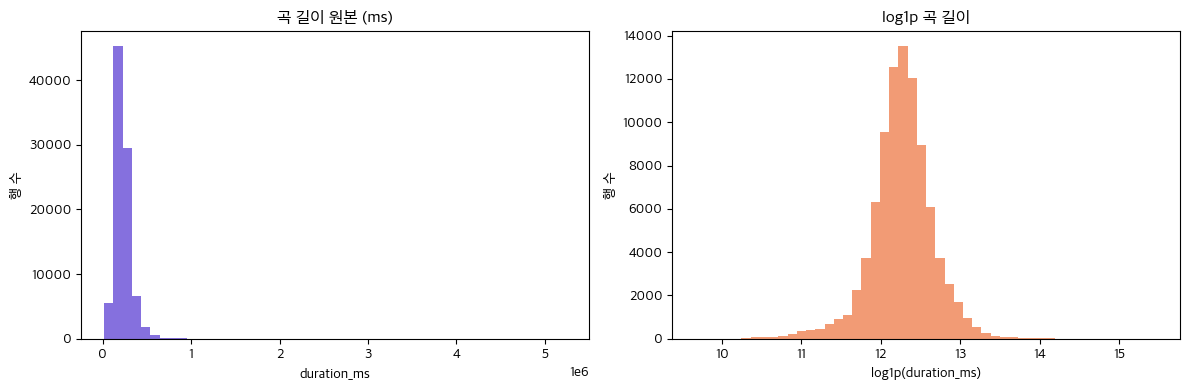

duration 버전,log1p,raw
K,,
2,0.2473,0.2493
3,0.1267,0.1311
4,0.1208,0.1254
5,0.1285,0.1317
6,0.1379,0.1403
7,0.1414,0.1451
8,0.1412,0.1435
9,0.1286,0.1397
10,0.1124,0.1204


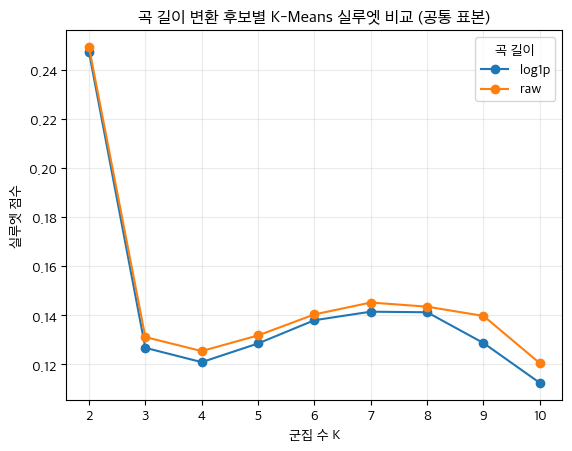

최종 곡 길이 처리: raw
최종 모델 입력 행·열: (89578, 28)
연속형 열: ['duration_ms', 'danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
원-핫 인코딩 열: ['key_0', 'key_1', 'key_10', 'key_11', 'key_2', 'key_3', 'key_4', 'key_5', 'key_6', 'key_7', 'key_8', 'key_9', 'mode_0', 'mode_1', 'time_signature_1', 'time_signature_3', 'time_signature_4', 'time_signature_5']


,duration_ms,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,...,key_6,key_7,key_8,key_9,mode_0,mode_1,time_signature_1,time_signature_3,time_signature_4,time_signature_5
0,-0.646945,0.860621,-0.638892,0.212376,-0.010563,-0.931588,-0.534087,0.254388,-0.885460,0.297864,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,-0.271195,0.330007,0.573418,0.565208,-0.384725,-0.933067,-0.431966,0.069150,0.303764,0.193916,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,-0.595997,1.550990,0.170618,0.607501,-0.451792,0.754294,-0.534095,0.007404,1.447249,0.091146,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3,-0.483247,-0.012325,1.289072,0.927309,-0.470323,-0.958710,-0.534079,0.794666,-0.633893,0.194152,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,0.129474,0.495467,0.311403,0.632800,1.459609,-0.676340,-0.533201,-0.465983,-1.079852,-0.525138,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


In [202]:
# 원본 곡 길이와 log1p 곡 길이의 분포 및 K-Means 실루엣을 같은 표본에서 비교합니다.
df["duration_log1p"] = np.log1p(df["duration_ms"])
print("곡 길이 왜도 비교 (절댓값이 작을수록 덜 치우친 분포)")
display(pd.Series({"duration_ms 원본": df["duration_ms"].skew(),
                   "log1p(duration_ms)": df["duration_log1p"].skew()}, name="왜도").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["duration_ms"], bins=50, color="#7057d9", alpha=0.85)
axes[0].set_title("곡 길이 원본 (ms)")
axes[0].set_xlabel("duration_ms")
axes[0].set_ylabel("행 수")
axes[1].hist(df["duration_log1p"], bins=50, color="#f08a5d", alpha=0.85)
axes[1].set_title("log1p 곡 길이")
axes[1].set_xlabel("log1p(duration_ms)")
axes[1].set_ylabel("행 수")
plt.tight_layout()
plt.show()

# 범주형 세 특성은 모든 후보에서 똑같이 원-핫 인코딩합니다.
categorical = df[["key", "mode", "time_signature"]].astype(int).astype(str)
X_categorical = pd.get_dummies(
    categorical,
    columns=["key", "mode", "time_signature"],
    prefix=["key", "mode", "time_signature"],
    dtype=np.float32,
)
X_categorical.index = df.index
sample_positions = np.random.RandomState(RANDOM_STATE).choice(
    len(df), size=min(1200, len(df)), replace=False
)
duration_rows = []
for version in ["raw", "log1p"]:
    candidate_continuous = df[continuous_cols].copy()
    candidate_continuous["duration_ms"] = (
        df["duration_ms"] if version == "raw" else df["duration_log1p"]
    )
    candidate_scaled = StandardScaler().fit_transform(candidate_continuous)
    candidate_X = np.column_stack([candidate_scaled, X_categorical.to_numpy()])
    candidate_sample = candidate_X[sample_positions]
    for k in range(2, 11):
        with threadpool_limits(limits=1):
            candidate_labels = KMeans(
                n_clusters=k, random_state=RANDOM_STATE, n_init=10
            ).fit_predict(candidate_sample)
        duration_rows.append({
            "duration 버전": version,
            "K": k,
            "실루엣 점수": silhouette_score(candidate_sample, candidate_labels),
        })
duration_comparison = pd.DataFrame(duration_rows)
display(duration_comparison.pivot(index="K", columns="duration 버전", values="실루엣 점수").round(4))
for version, group in duration_comparison.groupby("duration 버전"):
    plt.plot(group["K"], group["실루엣 점수"], marker="o", label=version)
plt.title("곡 길이 변환 후보별 K-Means 실루엣 비교 (공통 표본)")
plt.xlabel("군집 수 K")
plt.ylabel("실루엣 점수")
plt.xticks(range(2, 11))
plt.legend(title="곡 길이")
plt.grid(alpha=0.25)
plt.show()

# 위 분포·점수를 확인한 뒤 raw 또는 log1p로 선택합니다.
DURATION_VERSION = "raw"  # 비교 후 log1p를 쓰려면 "log1p"로 변경
if DURATION_VERSION not in {"raw", "log1p"}:
    raise ValueError("DURATION_VERSION은 'raw' 또는 'log1p'여야 합니다.")
duration_feature = "duration_ms" if DURATION_VERSION == "raw" else "duration_log1p"
model_continuous = df[continuous_cols].drop(columns="duration_ms").copy()
model_continuous.insert(0, duration_feature, df[duration_feature])
continuous_model_cols = model_continuous.columns.tolist()
scaler = StandardScaler()
X_continuous = pd.DataFrame(
    scaler.fit_transform(model_continuous),
    columns=continuous_model_cols,
    index=df.index,
)

X = pd.concat([X_continuous, X_categorical], axis=1).astype("float32")
assert "popularity" not in X.columns and "track_id" not in X.columns
assert "track_genre" not in X.columns and len(X) == len(df)

track_info = df[
    [c for c in ["track_id", "track_name", "artists", "album_name",
                 "popularity", "explicit", "track_genre"] if c in df.columns]
].copy()
print(f"최종 곡 길이 처리: {DURATION_VERSION}")
print(f"최종 모델 입력 행·열: {X.shape}")
print(f"연속형 열: {continuous_model_cols}")
print(f"원-핫 인코딩 열: {X_categorical.columns.tolist()}")
display(X.head())

## 군집화 직전: 최종 전처리 데이터 확인

먼저 최종 특성의 스케일링 전 분포를 보고, 이어서 같은 특성을 StandardScaler로 표준화한 뒤 분포를 비교합니다. 마지막 그래프는 원-핫 범주 비율입니다. 모두 군집화에 실제 사용할 특성이고 popularity는 포함하지 않습니다.

최종 모델 입력 크기: (89578, 28)  |  duration 버전: raw
연속형 특성 평균 범위: -0.000 ~ 0.000
연속형 특성 표준편차 범위: 1.000 ~ 1.000


/var/folders/4v/tf2tg78s6yd4n5__j_8dggcm0000gn/T/ipykernel_54838/470143760.py:11: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  plt.tight_layout()
/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


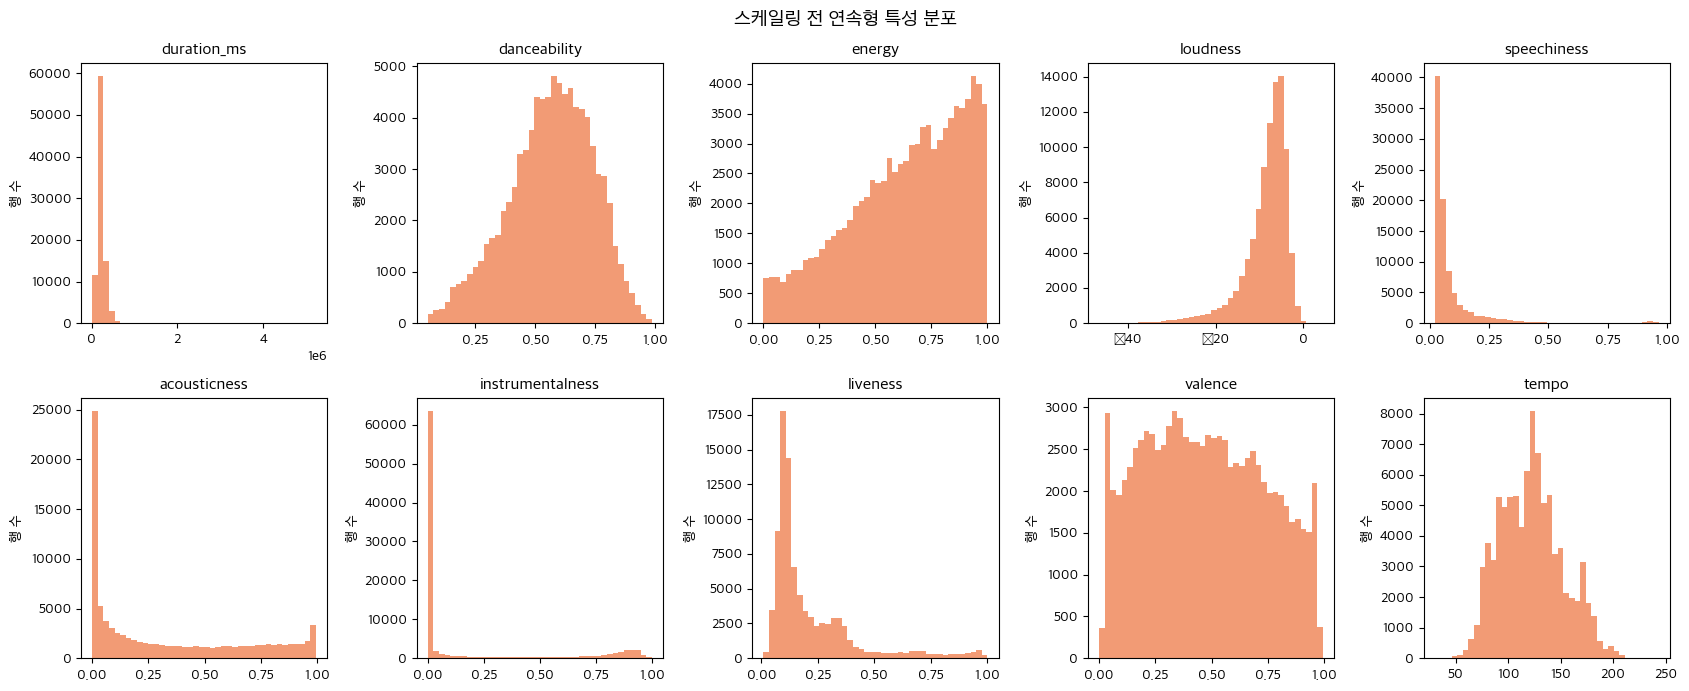

/var/folders/4v/tf2tg78s6yd4n5__j_8dggcm0000gn/T/ipykernel_54838/470143760.py:21: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  plt.tight_layout()


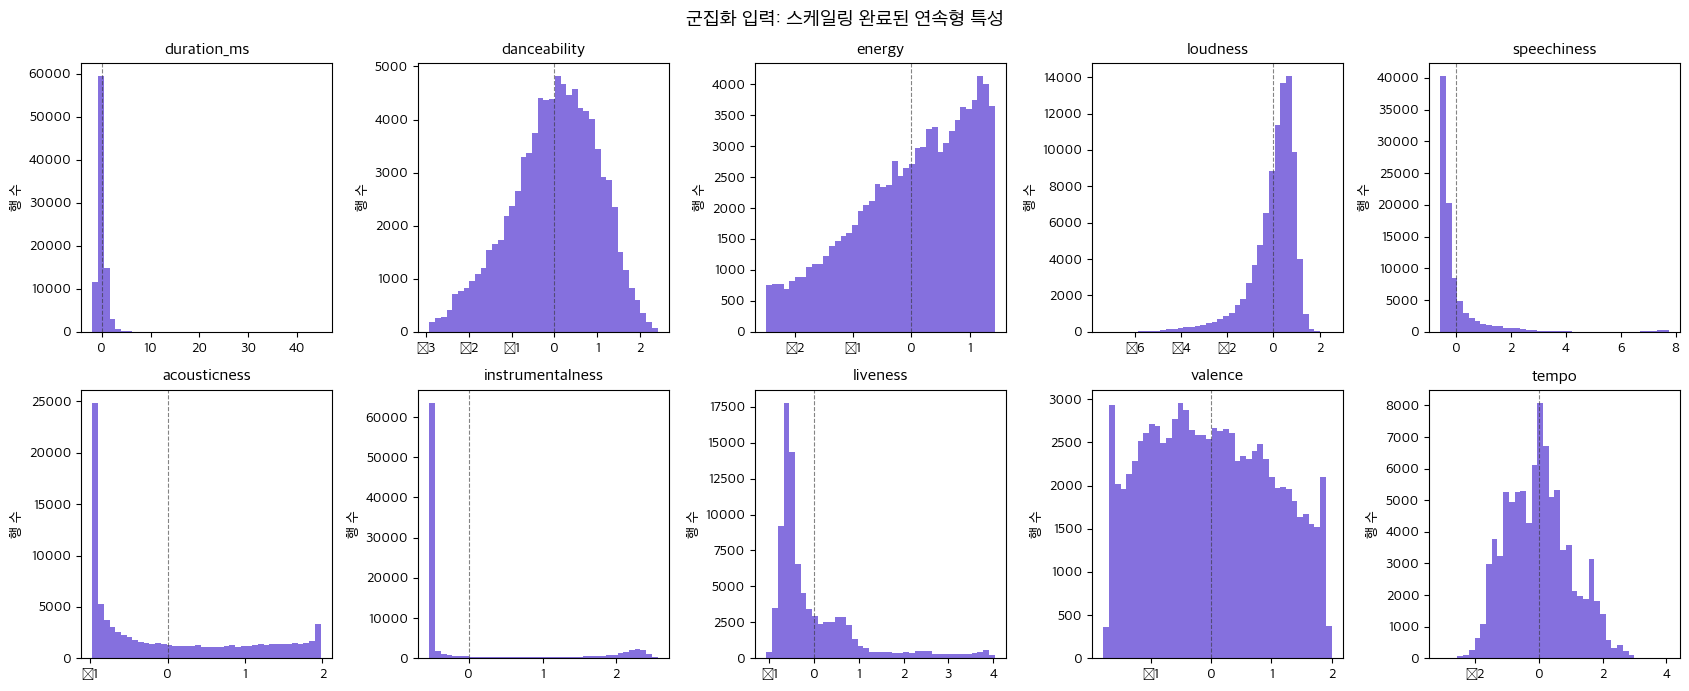

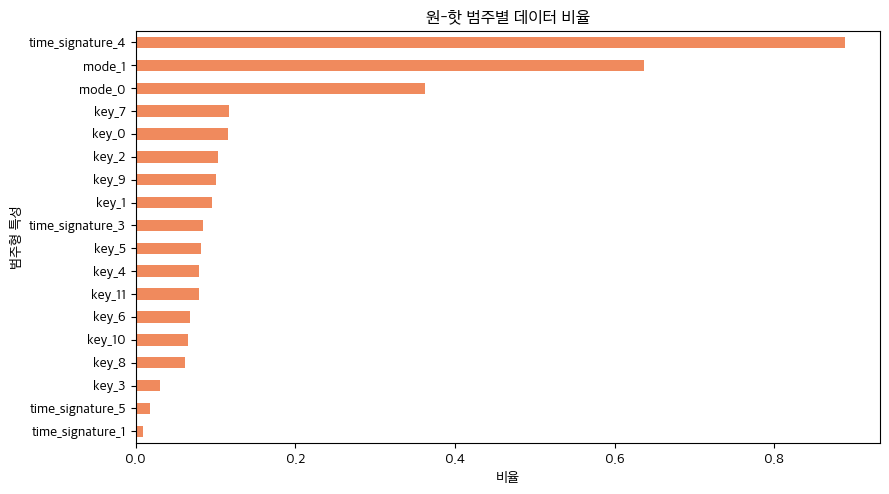

,count,mean,std,min,25%,50%,75%,max
duration_ms,89578.0,-0.0,1.0,-1.910,-0.502,-0.142,0.314,44.811
danceability,89578.0,-0.0,1.0,-2.920,-0.646,0.073,0.735,2.407
energy,89578.0,0.0,1.0,-2.485,-0.690,0.163,0.851,1.426
loudness,89578.0,-0.0,1.0,-7.361,-0.354,0.251,0.651,2.512
speechiness,89578.0,-0.0,1.0,-0.578,-0.455,-0.341,-0.014,7.743
acousticness,89578.0,0.0,1.0,-0.970,-0.919,-0.417,0.876,1.976
instrumentalness,89578.0,-0.0,1.0,-0.534,-0.534,-0.534,-0.243,2.561
liveness,89578.0,-0.0,1.0,-1.067,-0.609,-0.435,0.316,4.031
valence,89578.0,-0.0,1.0,-1.793,-0.840,-0.047,0.811,2.000
tempo,89578.0,-0.0,1.0,-3.099,-0.766,-0.008,0.600,4.076


In [203]:
print(f"최종 모델 입력 크기: {X.shape}  |  duration 버전: {DURATION_VERSION}")
print(f"연속형 특성 평균 범위: {X[continuous_model_cols].mean().min():.3f} ~ {X[continuous_model_cols].mean().max():.3f}")
print(f"연속형 특성 표준편차 범위: {X[continuous_model_cols].std().min():.3f} ~ {X[continuous_model_cols].std().max():.3f}")

fig, axes = plt.subplots(2, 5, figsize=(17, 7))
for ax, column in zip(axes.flat, continuous_model_cols):
    ax.hist(model_continuous[column], bins=40, color="#f08a5d", alpha=0.85)
    ax.set_title(column)
    ax.set_ylabel("행 수")
fig.suptitle("스케일링 전 연속형 특성 분포", fontsize=14)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(17, 7))
for ax, column in zip(axes.flat, continuous_model_cols):
    ax.hist(X[column], bins=40, color="#7057d9", alpha=0.85)
    ax.set_title(column)
    ax.set_ylabel("행 수")
    ax.axvline(0, color="#333333", linestyle="--", linewidth=0.8, alpha=0.6)
fig.suptitle("군집화 입력: 스케일링 완료된 연속형 특성", fontsize=14)
plt.tight_layout()
plt.show()

categorical_prevalence = X[X_categorical.columns].mean().sort_values()
ax = categorical_prevalence.plot(
    kind="barh", figsize=(9, max(4, len(categorical_prevalence) * 0.28)),
    color="#f08a5d"
)
ax.set_title("원-핫 범주별 데이터 비율")
ax.set_xlabel("비율")
ax.set_ylabel("범주형 특성")
plt.tight_layout()
plt.show()

display(X[continuous_model_cols].describe().T.round(3))

## 4. 베이스라인: K-Means

test1과 비교할 수 있도록 우선 K=6을 임시 기준으로 둡니다. 이 값이 최종 정답이라는 뜻은 아닙니다. 뒤의 여러 K와 다른 알고리즘의 결과를 보고 선택합니다.

In [204]:
# 모든 알고리즘을 같은 재현 가능한 표본에서 비교합니다.
MODEL_SAMPLE_SIZE = 1500
X_compare = X.sample(
    n=min(MODEL_SAMPLE_SIZE, len(X)),
    random_state=RANDOM_STATE,
)
X_compare_array = X_compare.to_numpy(dtype=np.float32)
df_compare = df.loc[X_compare.index].copy()

def evaluate_labels(X_values, labels):
    labels = np.asarray(labels)
    noise_mask = labels == -1
    valid_mask = ~noise_mask
    X_valid = X_values[valid_mask]
    labels_valid = labels[valid_mask]
    unique_labels = np.unique(labels_valid)
    sizes = pd.Series(labels_valid).value_counts()

    result = {
        "n_clusters": len(unique_labels),
        "noise_rate": float(noise_mask.mean()),
        "smallest_cluster": int(sizes.min()) if len(sizes) else 0,
        "largest_cluster": int(sizes.max()) if len(sizes) else 0,
        "silhouette": np.nan,
        "davies_bouldin": np.nan,
        "calinski_harabasz": np.nan,
    }
    if 2 <= len(unique_labels) < len(labels_valid):
        result["silhouette"] = silhouette_score(
            X_valid,
            labels_valid,
            sample_size=min(1000, len(labels_valid)),
            random_state=RANDOM_STATE,
        )
        result["davies_bouldin"] = davies_bouldin_score(X_valid, labels_valid)
        result["calinski_harabasz"] = calinski_harabasz_score(X_valid, labels_valid)
    return result

BASELINE_K = 6
with threadpool_limits(limits=4):
    baseline_kmeans = KMeans(
        n_clusters=BASELINE_K,
        n_init=10,
        random_state=RANDOM_STATE,
    )
    baseline_labels = baseline_kmeans.fit_predict(X_compare_array)

baseline_result = evaluate_labels(X_compare_array, baseline_labels)
baseline_result.update({
    "method": "KMeans baseline",
    "parameter": f"K={BASELINE_K}",
    "inertia": baseline_kmeans.inertia_,
})
display(pd.DataFrame([baseline_result]).round(4))
display(pd.Series(baseline_labels, name="cluster").value_counts().sort_index()
        .rename("곡 수").to_frame())

,n_clusters,noise_rate,smallest_cluster,largest_cluster,silhouette,davies_bouldin,calinski_harabasz,method,parameter,inertia
0,6,0.0,17,476,0.143,1.7516,208.1888,KMeans baseline,K=6,10012.8047


,곡 수
0,476
1,366
2,141
3,173
4,17
5,327


### K-Means 변수별 군집 분리 기여도: duration 원본 vs log1p

군집화에는 정답 라벨이 없으므로 지도학습의 feature importance와 같은 정답형 중요도는 없습니다. 여기서는 K=6으로 두 버전을 각각 군집화하고, 전체 군집 간 제곱합 중 각 원본 변수(원-핫 열은 원래 범주형 변수 단위로 합산)가 차지하는 비율을 비교합니다. 비율이 높으면 그 변수에서 군집 중심들이 더 크게 달라졌다는 뜻입니다. 두 버전은 같은 1,500곡 표본과 같은 나머지 특성·설정을 사용합니다. 이 값은 해당 K-Means 결과를 설명하는 지표이지 인과관계나 보편적인 중요도는 아닙니다.

duration 버전,log1p,raw
변수,,
key,0.08,0.08
mode,0.17,0.17
time_signature,0.26,0.26
duration_ms,1.65,0.86
liveness,3.80,3.86
tempo,3.95,4.24
danceability,8.15,8.06
valence,9.43,9.34
speechiness,10.30,10.34


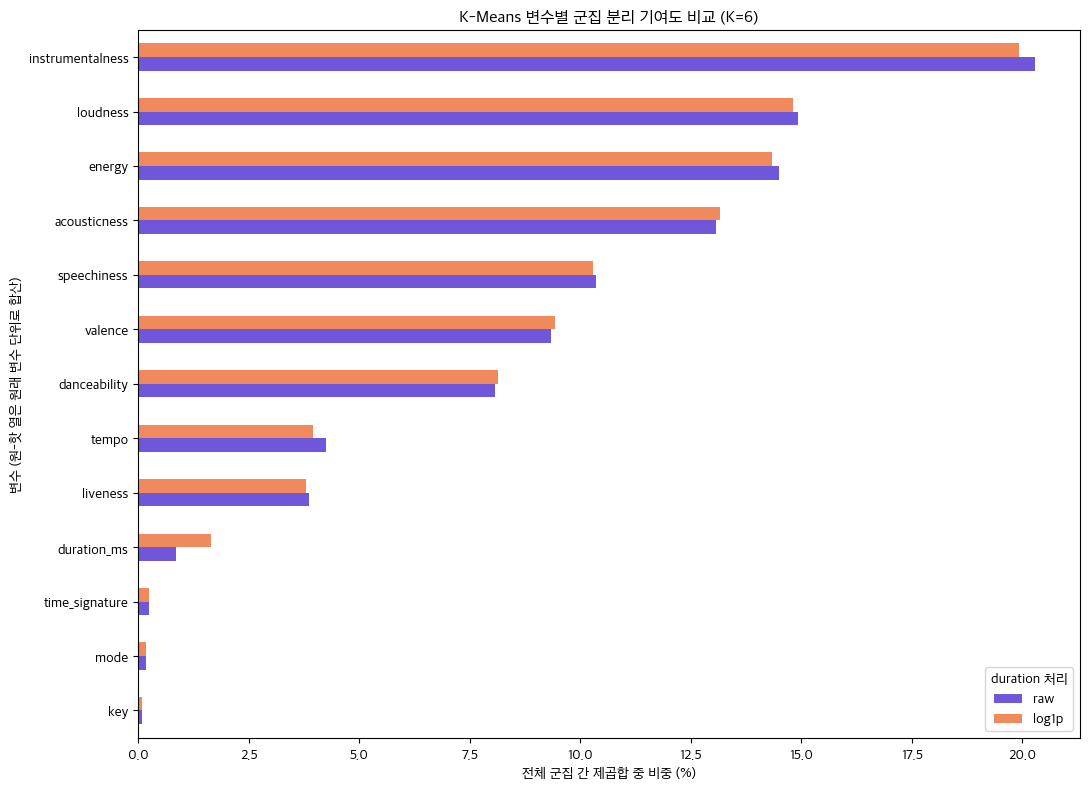

해석: 막대가 클수록 이 표본의 K-Means 군집 중심이 해당 변수에서 더 많이 구분됩니다.


In [205]:
importance_k = BASELINE_K
importance_rows = []
feature_groups = {column: [column] for column in continuous_cols}
for category in ["key", "mode", "time_signature"]:
    feature_groups[category] = [
        column for column in X_categorical.columns
        if column.startswith(f"{category}_")
    ]

for duration_version in ["raw", "log1p"]:
    variant_continuous = df[continuous_cols].copy()
    variant_continuous["duration_ms"] = (
        df["duration_ms"] if duration_version == "raw" else df["duration_log1p"]
    )
    variant_scaled = pd.DataFrame(
        StandardScaler().fit_transform(variant_continuous),
        columns=continuous_cols,
        index=df.index,
    )
    variant_X = pd.concat([variant_scaled, X_categorical], axis=1)
    variant_sample = variant_X.loc[X_compare.index].to_numpy(dtype=np.float32)

    with threadpool_limits(limits=4):
        variant_labels = KMeans(
            n_clusters=importance_k,
            n_init=10,
            random_state=RANDOM_STATE,
        ).fit_predict(variant_sample)

    overall_mean = variant_sample.mean(axis=0)
    between_cluster_ss = np.zeros(variant_sample.shape[1], dtype=float)
    for cluster_id in np.unique(variant_labels):
        cluster_mask = variant_labels == cluster_id
        cluster_values = variant_sample[cluster_mask]
        between_cluster_ss += len(cluster_values) * (
            cluster_values.mean(axis=0) - overall_mean
        ) ** 2

    column_positions = {name: i for i, name in enumerate(variant_X.columns)}
    total_between = between_cluster_ss.sum()
    for feature_name, columns in feature_groups.items():
        positions = [column_positions[column] for column in columns]
        contribution = between_cluster_ss[positions].sum() / total_between * 100
        importance_rows.append({
            "duration 버전": duration_version,
            "변수": feature_name,
            "군집 분리 기여도(%)": contribution,
        })

importance_long = pd.DataFrame(importance_rows)
importance_wide = importance_long.pivot(
    index="변수", columns="duration 버전", values="군집 분리 기여도(%)"
)
plot_order = importance_wide.max(axis=1).sort_values().index
display(importance_wide.loc[plot_order].round(2))

ax = importance_wide.loc[plot_order, ["raw", "log1p"]].plot(
    kind="barh", figsize=(11, 8), color=["#7057d9", "#f08a5d"]
)
ax.set_title(f"K-Means 변수별 군집 분리 기여도 비교 (K={importance_k})")
ax.set_xlabel("전체 군집 간 제곱합 중 비중 (%)")
ax.set_ylabel("변수 (원-핫 열은 원래 변수 단위로 합산)")
ax.legend(title="duration 처리")
plt.tight_layout()
plt.show()

print("해석: 막대가 클수록 이 표본의 K-Means 군집 중심이 해당 변수에서 더 많이 구분됩니다.")

## 5. 다른 군집화 방법과 파라미터 탐색

모든 방법을 같은 표본·같은 특성으로 비교합니다. 지표는 실루엣(클수록 좋음), Davies–Bouldin(작을수록 좋음), Calinski–Harabasz(클수록 좋음), 군집 수와 군집 크기입니다. 지표 하나만으로 자동 선택하지 않습니다.

알고리즘마다 조절하는 값이 다릅니다.

- K-Means: 군집 수 K. inertia의 엘보우와 실루엣 등을 확인합니다.
- GMM: 성분 수. K-Means inertia가 아니라 BIC/AIC를 확인합니다(보통 낮을수록 좋음).
- DBSCAN: 군집 수를 직접 지정하지 않습니다. eps와 min_samples를 조절하고, k-distance와 잡음 비율·군집 크기를 봅니다.
- Mean Shift: 군집 수를 직접 지정하지 않습니다. bandwidth에 따라 결과 군집 수가 달라집니다.
- KNN은 군집화가 아니라 이웃 검색/추천용이므로 여기서 군집 알고리즘 비교 대상으로 취급하지 않습니다.

In [206]:
K_VALUES = range(2, 11)
comparison_rows = []
candidate_labels = {}

with threadpool_limits(limits=4):
    for k in K_VALUES:
        km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
        km_labels = km.fit_predict(X_compare_array)
        row = evaluate_labels(X_compare_array, km_labels)
        row.update({
            "method": "KMeans",
            "parameter": f"K={k}",
            "k": k,
            "inertia": km.inertia_,
            "BIC": np.nan,
            "AIC": np.nan,
        })
        comparison_rows.append(row)
        candidate_labels[("KMeans", k)] = km_labels

        gmm = GaussianMixture(
            n_components=k,
            covariance_type="diag",
            n_init=1,
            max_iter=150,
            reg_covar=1e-4,
            random_state=RANDOM_STATE,
        )
        gmm_labels = gmm.fit_predict(X_compare_array)
        row = evaluate_labels(X_compare_array, gmm_labels)
        row.update({
            "method": "GMM",
            "parameter": f"components={k}",
            "k": k,
            "inertia": np.nan,
            "BIC": gmm.bic(X_compare_array),
            "AIC": gmm.aic(X_compare_array),
        })
        comparison_rows.append(row)
        candidate_labels[("GMM", k)] = gmm_labels

comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table.round(4))

,n_clusters,noise_rate,smallest_cluster,largest_cluster,silhouette,davies_bouldin,calinski_harabasz,method,parameter,k,inertia,BIC,AIC
0,2,0.0,318,1182,0.2438,1.6774,345.2507,KMeans,K=2,2,13807.0488,NaN,NaN
1,2,0.0,199,1301,0.1727,3.6028,57.7296,GMM,components=2,2,NaN,4099.2437,3498.8498
2,3,0.0,290,702,0.1306,2.2295,262.8816,KMeans,K=3,3,12573.3242,NaN,NaN
3,3,0.0,206,666,0.0190,4.5645,57.4582,GMM,components=3,3,NaN,-21064.9877,-21968.2351
4,4,0.0,158,550,0.1295,2.1156,229.6342,KMeans,K=4,4,11632.4961,NaN,NaN
5,4,0.0,109,741,0.0461,3.7009,56.5843,GMM,components=4,4,NaN,-21069.8789,-22275.9799
6,5,0.0,97,509,0.1340,1.9318,215.5060,KMeans,K=5,5,10775.8242,NaN,NaN
7,5,0.0,82,618,0.0047,5.1876,74.1670,GMM,components=5,5,NaN,-30231.2898,-31740.2444
8,6,0.0,17,476,0.1430,1.7516,208.1888,KMeans,K=6,6,10012.8047,NaN,NaN
9,6,0.0,16,585,-0.0436,5.8506,22.7443,GMM,components=6,6,NaN,-62960.3130,-64772.1211


In [207]:
# DBSCAN은 eps를 k-nearest-neighbor 거리 분포에서 후보로 정합니다.
dbscan_rows = []
k_distance_curves = {}
EPS_QUANTILES = [0.90, 0.95, 0.98, 0.99]
MIN_SAMPLES_VALUES = [10, 20]

for min_samples in MIN_SAMPLES_VALUES:
    neighbors = NearestNeighbors(n_neighbors=min_samples + 1, n_jobs=-1)
    neighbors.fit(X_compare_array)
    distances, _ = neighbors.kneighbors(X_compare_array)
    k_distances = np.sort(distances[:, -1])
    k_distance_curves[min_samples] = k_distances
    eps_candidates = np.unique(np.quantile(k_distances, EPS_QUANTILES))

    for eps in eps_candidates:
        model = DBSCAN(eps=float(eps), min_samples=min_samples, n_jobs=-1)
        labels = model.fit_predict(X_compare_array)
        row = evaluate_labels(X_compare_array, labels)
        row.update({
            "method": "DBSCAN",
            "parameter": f"eps={eps:.4f}, min_samples={min_samples}",
            "eps": float(eps),
            "min_samples": min_samples,
        })
        dbscan_rows.append(row)
        candidate_labels[("DBSCAN", float(eps), min_samples)] = labels

dbscan_table = pd.DataFrame(dbscan_rows)
display(dbscan_table.round(4))

,n_clusters,noise_rate,smallest_cluster,largest_cluster,silhouette,davies_bouldin,calinski_harabasz,method,parameter,eps,min_samples
0,1,0.0340,1449,1449,NaN,NaN,NaN,DBSCAN,"eps=2.8405, min_samples=10",2.8405,10
1,1,0.0200,1470,1470,NaN,NaN,NaN,DBSCAN,"eps=3.1314, min_samples=10",3.1314,10
2,2,0.0020,10,1487,0.5028,0.6547,62.1815,DBSCAN,"eps=3.8626, min_samples=10",3.8626,10
3,1,0.0007,1499,1499,NaN,NaN,NaN,DBSCAN,"eps=4.2910, min_samples=10",4.2910,10
4,1,0.0273,1459,1459,NaN,NaN,NaN,DBSCAN,"eps=3.0845, min_samples=20",3.0845,20
5,1,0.0173,1474,1474,NaN,NaN,NaN,DBSCAN,"eps=3.4102, min_samples=20",3.4102,20
6,1,0.0087,1487,1487,NaN,NaN,NaN,DBSCAN,"eps=4.3016, min_samples=20",4.3016,20
7,1,0.0020,1497,1497,NaN,NaN,NaN,DBSCAN,"eps=4.9335, min_samples=20",4.9335,20


In [208]:
# Mean Shift의 bandwidth 후보를 여러 분위수에서 추정해 비교합니다.
meanshift_rows = []
meanshift_bandwidths = {}

for quantile in [0.10, 0.15, 0.20]:
    bandwidth = estimate_bandwidth(
        X_compare_array,
        quantile=quantile,
        n_samples=min(500, len(X_compare_array)),
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    if not np.isfinite(bandwidth) or bandwidth <= 0:
        print(f"quantile={quantile}: 유효하지 않은 bandwidth({bandwidth}), 건너뜁니다.")
        continue

    model = MeanShift(
        bandwidth=bandwidth,
        bin_seeding=True,
        n_jobs=-1,
    )
    labels = model.fit_predict(X_compare_array)
    row = evaluate_labels(X_compare_array, labels)
    row.update({
        "method": "MeanShift",
        "parameter": f"quantile={quantile}, bandwidth={bandwidth:.4f}",
        "quantile": quantile,
        "bandwidth": float(bandwidth),
    })
    meanshift_rows.append(row)
    meanshift_bandwidths[quantile] = float(bandwidth)
    candidate_labels[("MeanShift", float(bandwidth))] = labels

meanshift_table = pd.DataFrame(meanshift_rows)
display(meanshift_table.round(4))

,n_clusters,noise_rate,smallest_cluster,largest_cluster,silhouette,davies_bouldin,calinski_harabasz,method,parameter,quantile,bandwidth
0,5,0.0,12,1363,0.2166,2.0246,83.2892,MeanShift,"quantile=0.1, bandwidth=3.2048",0.10,3.2048
1,4,0.0,10,1391,0.2148,1.2652,94.7523,MeanShift,"quantile=0.15, bandwidth=3.4197",0.15,3.4197
2,2,0.0,16,1484,0.4770,0.8249,79.7131,MeanShift,"quantile=0.2, bandwidth=3.5912",0.20,3.5912


## 6. 파라미터 곡선과 최종 모델 선택

K-Means에는 inertia 엘보우, GMM에는 BIC/AIC, 밀도 기반 방법에는 거리·잡음·군집 수 곡선을 확인합니다. “모든 모델의 엘보우”를 억지로 그리는 대신, 각 모델의 의미 있는 선택 기준을 사용합니다.

최종 선택에서는 군집 품질 지표뿐 아니라 너무 작은 군집이 생기는지, 잡음이 과도한지, 실제 곡 추천에 적용할 때 새 곡을 배정할 수 있는지도 함께 고려합니다.

/var/folders/4v/tf2tg78s6yd4n5__j_8dggcm0000gn/T/ipykernel_54838/1288296343.py:34: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  plt.tight_layout()
/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


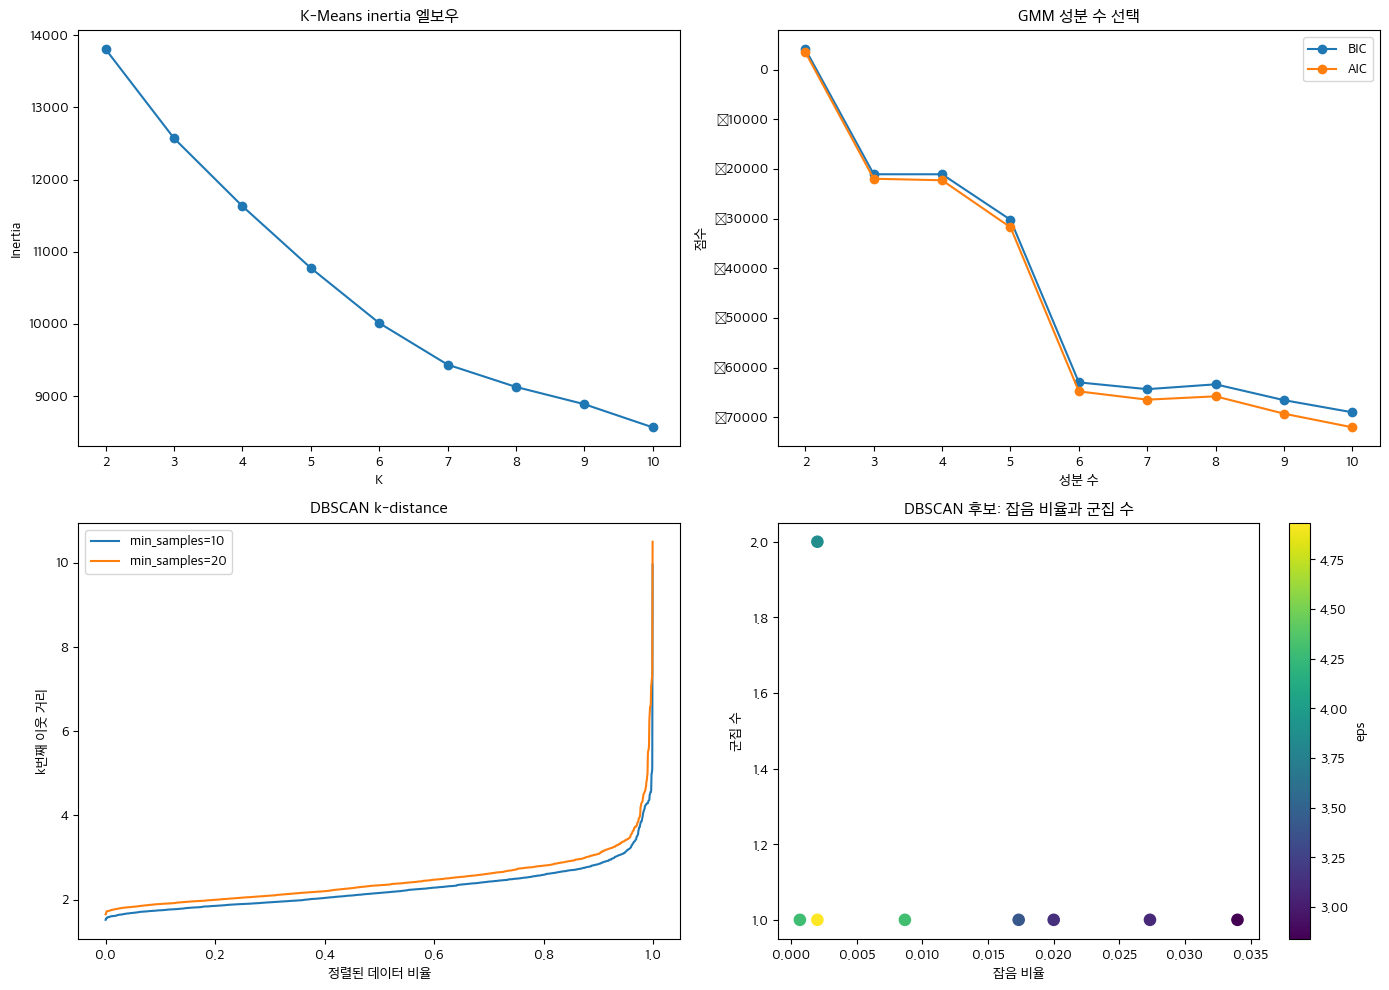

K-Means / GMM 비교표


,method,parameter,n_clusters,silhouette,davies_bouldin,calinski_harabasz,inertia,BIC,AIC
1,GMM,components=2,2,0.1727,3.6028,57.7296,NaN,4099.2437,3498.8498
3,GMM,components=3,3,0.0190,4.5645,57.4582,NaN,-21064.9877,-21968.2351
5,GMM,components=4,4,0.0461,3.7009,56.5843,NaN,-21069.8789,-22275.9799
7,GMM,components=5,5,0.0047,5.1876,74.1670,NaN,-30231.2898,-31740.2444
9,GMM,components=6,6,-0.0436,5.8506,22.7443,NaN,-62960.3130,-64772.1211
11,GMM,components=7,7,-0.0345,4.6335,30.2769,NaN,-64326.2326,-66440.8943
13,GMM,components=8,8,-0.0434,4.7105,26.7205,NaN,-63351.8293,-65769.3445
15,GMM,components=9,9,-0.0410,4.8087,29.3983,NaN,-66537.2002,-69257.5691
17,GMM,components=10,10,-0.0628,4.5901,21.7320,NaN,-68982.6867,-72005.9091
0,KMeans,K=2,2,0.2438,1.6774,345.2507,13807.0488,NaN,NaN


DBSCAN 후보


,parameter,n_clusters,noise_rate,smallest_cluster,largest_cluster,silhouette
0,"eps=2.8405, min_samples=10",1,0.0340,1449,1449,NaN
1,"eps=3.1314, min_samples=10",1,0.0200,1470,1470,NaN
2,"eps=3.8626, min_samples=10",2,0.0020,10,1487,0.5028
3,"eps=4.2910, min_samples=10",1,0.0007,1499,1499,NaN
4,"eps=3.0845, min_samples=20",1,0.0273,1459,1459,NaN
5,"eps=3.4102, min_samples=20",1,0.0173,1474,1474,NaN
6,"eps=4.3016, min_samples=20",1,0.0087,1487,1487,NaN
7,"eps=4.9335, min_samples=20",1,0.0020,1497,1497,NaN


Mean Shift 후보


,parameter,n_clusters,noise_rate,smallest_cluster,largest_cluster,silhouette
0,"quantile=0.1, bandwidth=3.2048",5,0.0,12,1363,0.2166
1,"quantile=0.15, bandwidth=3.4197",4,0.0,10,1391,0.2148
2,"quantile=0.2, bandwidth=3.5912",2,0.0,16,1484,0.4770


In [209]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

km_table = comparison_table[comparison_table["method"] == "KMeans"].sort_values("k")
axes[0, 0].plot(km_table["k"], km_table["inertia"], marker="o")
axes[0, 0].set(title="K-Means inertia 엘보우", xlabel="K", ylabel="Inertia")

gmm_table = comparison_table[comparison_table["method"] == "GMM"].sort_values("k")
axes[0, 1].plot(gmm_table["k"], gmm_table["BIC"], marker="o", label="BIC")
axes[0, 1].plot(gmm_table["k"], gmm_table["AIC"], marker="o", label="AIC")
axes[0, 1].set(title="GMM 성분 수 선택", xlabel="성분 수", ylabel="점수")
axes[0, 1].legend()

for min_samples, curve in k_distance_curves.items():
    axes[1, 0].plot(np.arange(len(curve)) / len(curve), curve,
                    label=f"min_samples={min_samples}")
axes[1, 0].set(title="DBSCAN k-distance", xlabel="정렬된 데이터 비율",
               ylabel="k번째 이웃 거리")
axes[1, 0].legend()

if len(dbscan_table):
    db_curve = dbscan_table.groupby("min_samples").agg(
        eps=("eps", "mean"),
        noise_rate=("noise_rate", "mean"),
        n_clusters=("n_clusters", "mean"),
    )
    axes[1, 1].scatter(dbscan_table["noise_rate"], dbscan_table["n_clusters"],
                       c=dbscan_table["eps"], cmap="viridis", s=65)
    axes[1, 1].set(title="DBSCAN 후보: 잡음 비율과 군집 수",
                   xlabel="잡음 비율", ylabel="군집 수")
    plt.colorbar(axes[1, 1].collections[0], ax=axes[1, 1], label="eps")
else:
    axes[1, 1].set_visible(False)

plt.tight_layout()
plt.show()

print("K-Means / GMM 비교표")
display(comparison_table.sort_values(
    ["method", "k"]
)[["method", "parameter", "n_clusters", "silhouette",
   "davies_bouldin", "calinski_harabasz", "inertia", "BIC", "AIC"]].round(4))

print("DBSCAN 후보")
display(dbscan_table[["parameter", "n_clusters", "noise_rate",
                      "smallest_cluster", "largest_cluster", "silhouette"]].round(4))

print("Mean Shift 후보")
display(meanshift_table[["parameter", "n_clusters", "noise_rate",
                         "smallest_cluster", "largest_cluster",
                         "silhouette"]].round(4))

### K-Means 군집 수별 실루엣 분석 및 PCA 시각화

K=2~10 각각의 실루엣 계수 분포와 평균 점수를 비교하고, 같은 비교 표본의 군집을 PCA 2차원 산점도로 나란히 확인합니다. PCA는 눈으로 보기 위한 투영이며, K-Means 학습은 스케일링된 전체 특성 공간에서 수행합니다. 계산과 시각화는 알고리즘 비교에 사용한 동일 표본(최대 1,500곡)을 사용합니다.

/var/folders/4v/tf2tg78s6yd4n5__j_8dggcm0000gn/T/ipykernel_54838/3135131592.py:35: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  plt.tight_layout(rect=[0, 0, 1, 0.97])
/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


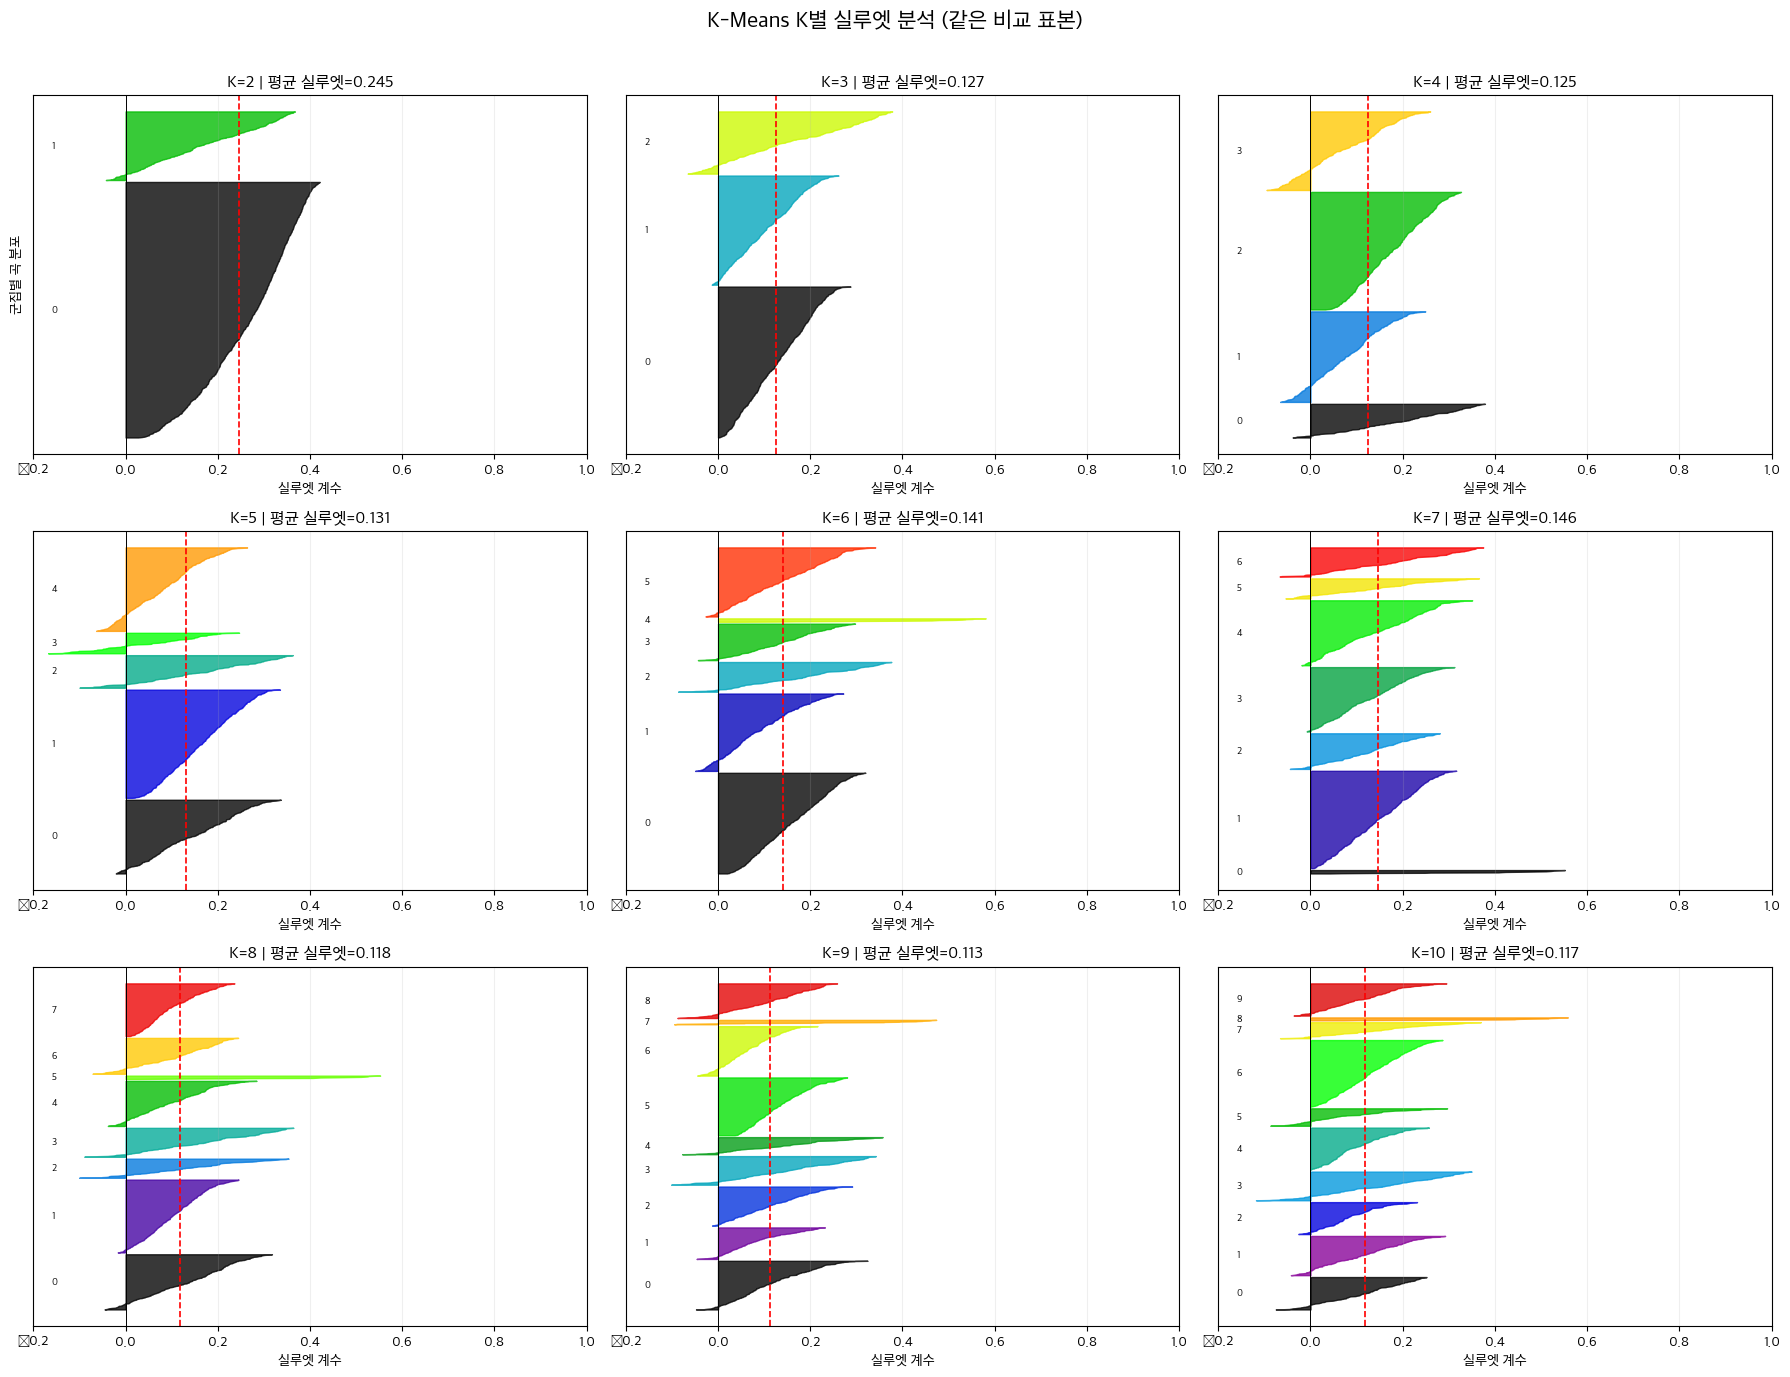

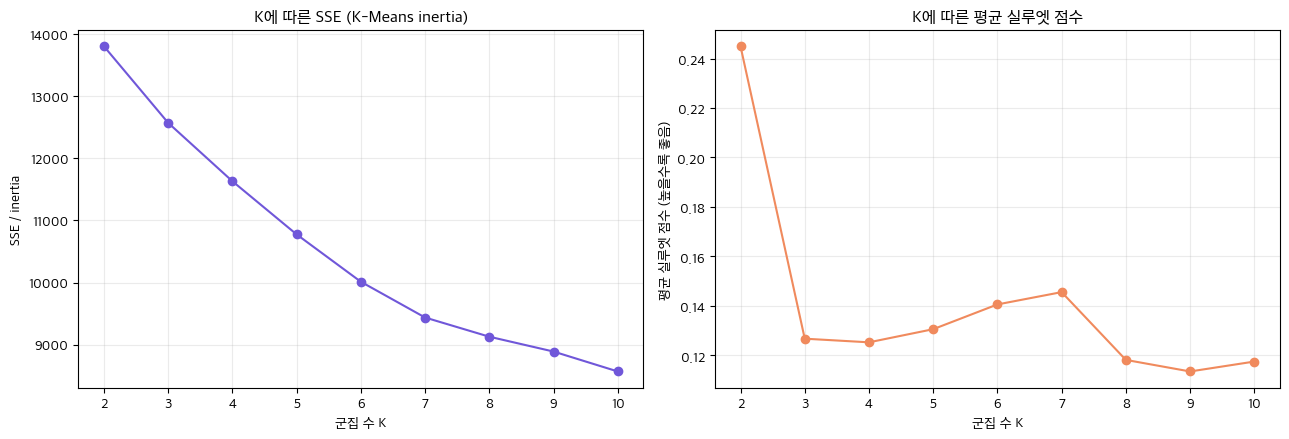

SSE는 K가 늘면 보통 감소합니다. 최솟값보다 감소 폭이 완만해지는 엘보우 지점을 확인하세요.


/var/folders/4v/tf2tg78s6yd4n5__j_8dggcm0000gn/T/ipykernel_54838/3135131592.py:79: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  plt.tight_layout(rect=[0, 0, 1, 0.97])
/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


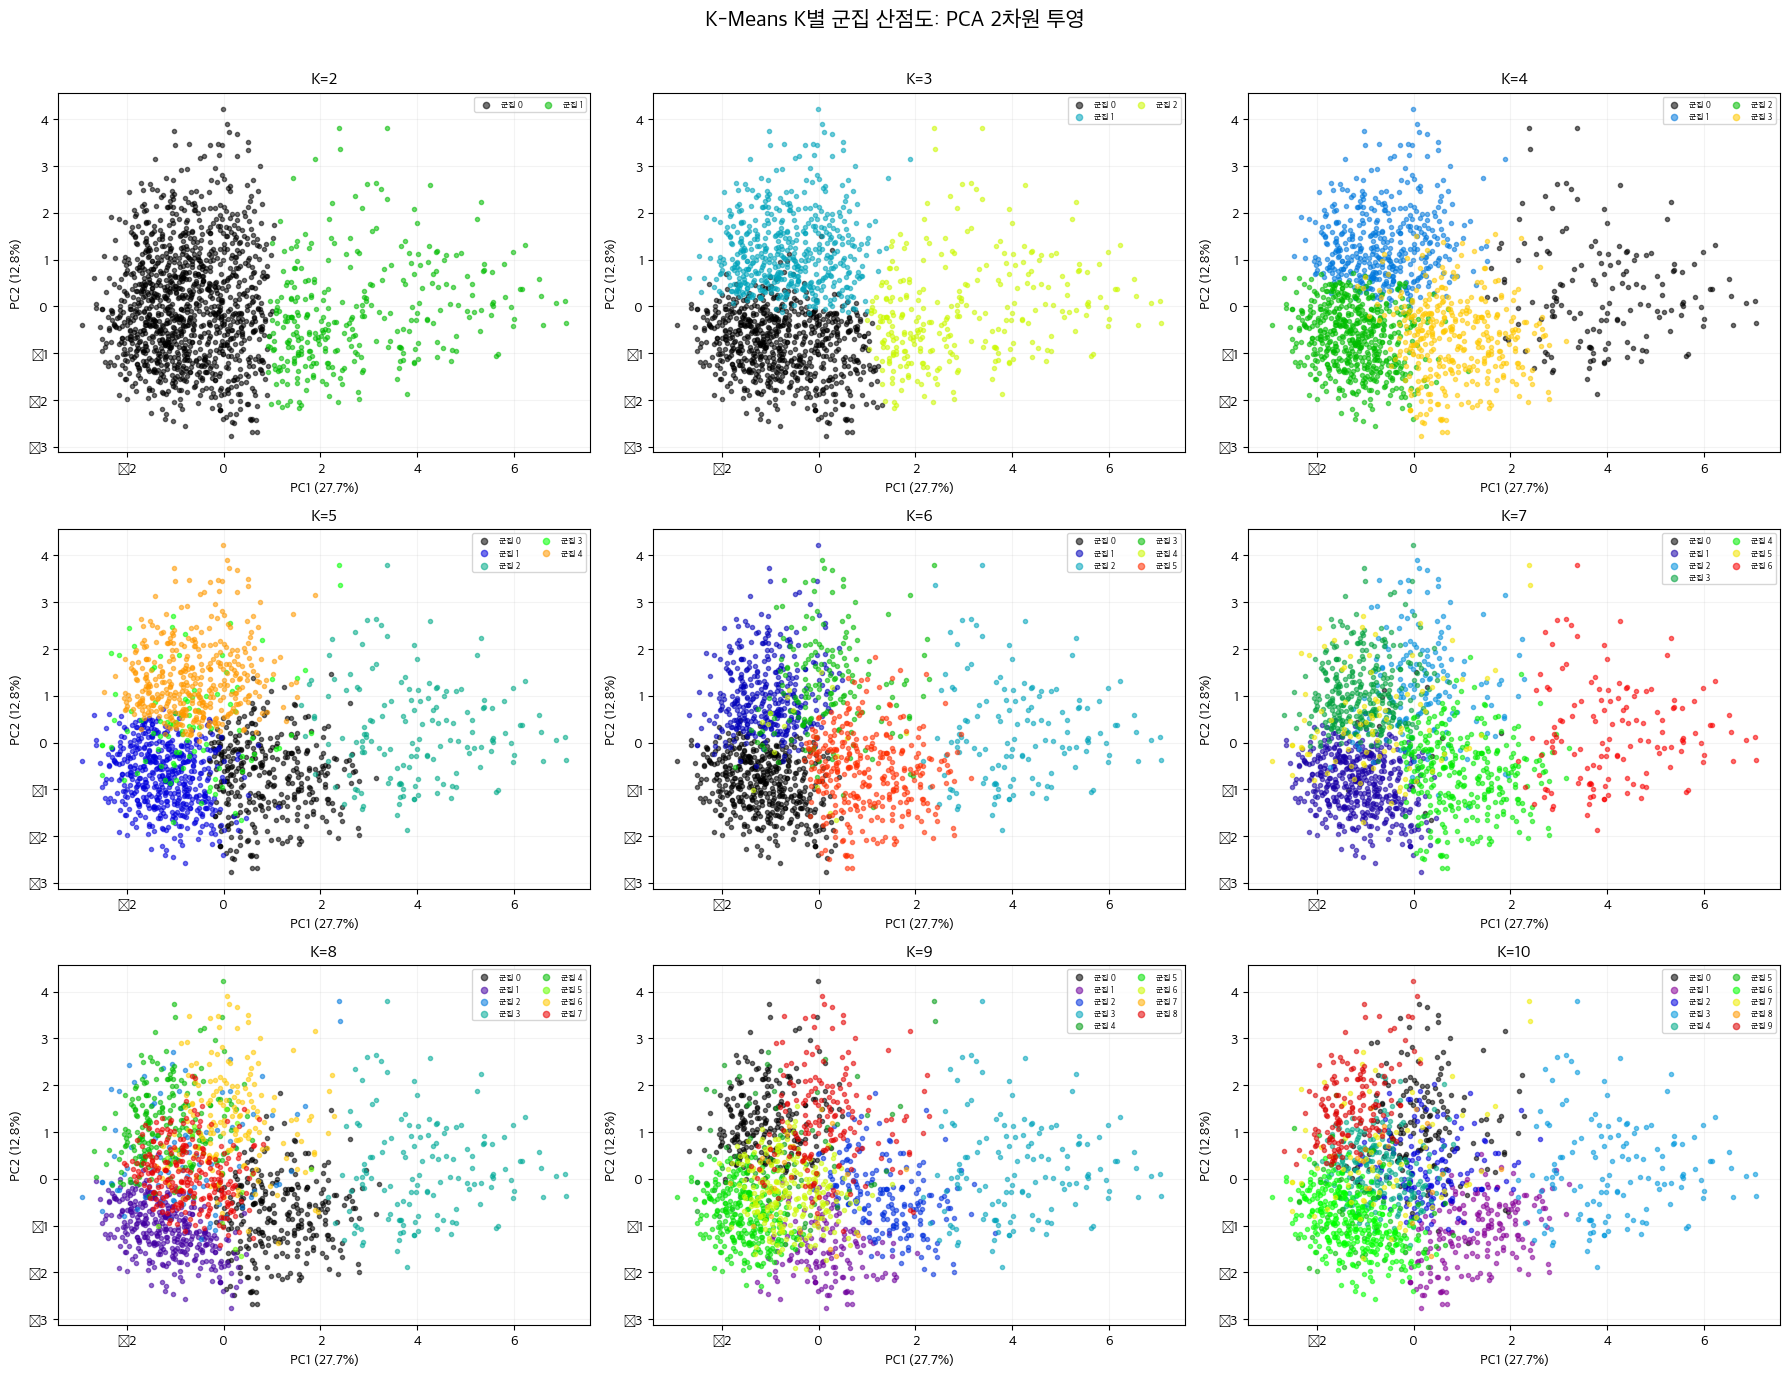

참고: 산점도는 PCA로 축약한 시각화이며, 실제 K-Means 군집은 전체 특성 공간에서 계산했습니다.


In [210]:
KMEANS_VIS_K_VALUES = range(2, 11)
silhouette_mean_rows = []

# 위에서 같은 표본으로 학습한 K-Means 결과(candidate_labels)를 재사용합니다.
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, k in zip(axes.flat, KMEANS_VIS_K_VALUES):
    labels = candidate_labels[("KMeans", k)]
    sample_silhouette_values = silhouette_samples(X_compare_array, labels)
    average_silhouette = sample_silhouette_values.mean()
    silhouette_mean_rows.append({"k": k, "mean_silhouette": average_silhouette})

    y_lower = 10
    for cluster_id in range(k):
        cluster_values = np.sort(sample_silhouette_values[labels == cluster_id])
        cluster_size = len(cluster_values)
        y_upper = y_lower + cluster_size
        color = plt.cm.nipy_spectral(cluster_id / max(k, 1))
        ax.fill_betweenx(
            np.arange(y_lower, y_upper), 0, cluster_values,
            facecolor=color, edgecolor=color, alpha=0.78
        )
        ax.text(-0.16, y_lower + 0.5 * cluster_size, str(cluster_id),
                fontsize=7, va="center")
        y_lower = y_upper + 8

    ax.axvline(average_silhouette, color="red", linestyle="--", linewidth=1.2)
    ax.axvline(0, color="black", linewidth=0.7)
    ax.set_xlim(-0.2, 1.0)
    ax.set_title(f"K={k} | 평균 실루엣={average_silhouette:.3f}")
    ax.set_xlabel("실루엣 계수")
    ax.set_yticks([])
    ax.grid(axis="x", alpha=0.2)
axes[0, 0].set_ylabel("군집별 곡 분포")
fig.suptitle("K-Means K별 실루엣 분석 (같은 비교 표본)", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

# Inertia는 K-Means의 SSE(군집 내 제곱거리 합)입니다. 같은 표본에서
# K가 늘어날 때 SSE와 평균 실루엣 점수가 어떻게 변하는지 함께 확인합니다.
km_summary = comparison_table[comparison_table["method"] == "KMeans"].sort_values("k")
silhouette_summary = pd.DataFrame(silhouette_mean_rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(km_summary["k"], km_summary["inertia"], marker="o", color="#7057d9")
axes[0].set_title("K에 따른 SSE (K-Means inertia)")
axes[0].set_xlabel("군집 수 K")
axes[0].set_ylabel("SSE / inertia")
axes[0].set_xticks(list(KMEANS_VIS_K_VALUES))
axes[0].grid(alpha=0.25)
axes[1].plot(silhouette_summary["k"], silhouette_summary["mean_silhouette"],
             marker="o", color="#f08a5d")
axes[1].set_title("K에 따른 평균 실루엣 점수")
axes[1].set_xlabel("군집 수 K")
axes[1].set_ylabel("평균 실루엣 점수 (높을수록 좋음)")
axes[1].set_xticks(list(KMEANS_VIS_K_VALUES))
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()
print("SSE는 K가 늘면 보통 감소합니다. 최솟값보다 감소 폭이 완만해지는 엘보우 지점을 확인하세요.")

# PCA는 K별 군집 결과를 같은 좌표계에서 눈으로 비교하기 위한 2차원 투영입니다.
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_compare_2d = pca_2d.fit_transform(X_compare_array)
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, k in zip(axes.flat, KMEANS_VIS_K_VALUES):
    labels = candidate_labels[("KMeans", k)]
    colors = plt.cm.nipy_spectral(np.linspace(0, 1, k, endpoint=False))
    for cluster_id, color in enumerate(colors):
        mask = labels == cluster_id
        ax.scatter(
            X_compare_2d[mask, 0], X_compare_2d[mask, 1],
            s=9, alpha=0.55, color=color, label=f"군집 {cluster_id}"
        )
    ax.set_title(f"K={k}")
    ax.set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]:.1%})")
    ax.set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]:.1%})")
    ax.legend(fontsize=6, markerscale=1.5, ncol=2, loc="best")
    ax.grid(alpha=0.15)
fig.suptitle("K-Means K별 군집 산점도: PCA 2차원 투영", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()
print("참고: 산점도는 PCA로 축약한 시각화이며, 실제 K-Means 군집은 전체 특성 공간에서 계산했습니다.")

### 선택할 모델 지정

아래 값은 현재 임시 설정입니다. 비교표를 확인한 뒤 바꿔 실행하세요. K-Means/GMM은 전체 곡에 군집을 예측할 수 있습니다. DBSCAN/Mean Shift는 기본 구현에 새 데이터의 `predict`가 없으므로 여기서는 공정 비교에 쓴 표본에서 최종 결과를 해석합니다. 웹 앱에 적용할 경우 별도의 신규 곡 배정 규칙이 필요합니다.

In [211]:
FINAL_METHOD = "KMeans"  # "KMeans", "GMM", "DBSCAN", "MeanShift"
FINAL_N_CLUSTERS = 6       # K-Means 또는 GMM 선택 시 사용
FINAL_DBSCAN_EPS = None    # DBSCAN 선택 시 비교표의 eps 값을 입력
FINAL_DBSCAN_MIN_SAMPLES = 10
FINAL_MEANSHIFT_BANDWIDTH = None  # MeanShift 선택 시 비교표의 bandwidth 입력

if FINAL_METHOD == "KMeans":
    final_model = KMeans(
        n_clusters=FINAL_N_CLUSTERS,
        n_init=10,
        random_state=RANDOM_STATE,
    )
    with threadpool_limits(limits=4):
        final_labels = final_model.fit_predict(X.to_numpy(dtype=np.float32))
    df_final = df.copy()

elif FINAL_METHOD == "GMM":
    final_model = GaussianMixture(
        n_components=FINAL_N_CLUSTERS,
        covariance_type="diag",
        n_init=1,
        max_iter=150,
        reg_covar=1e-4,
        random_state=RANDOM_STATE,
    )
    with threadpool_limits(limits=4):
        final_labels = final_model.fit_predict(X.to_numpy(dtype=np.float32))
    df_final = df.copy()

elif FINAL_METHOD == "DBSCAN":
    if FINAL_DBSCAN_EPS is None:
        raise ValueError("DBSCAN 결과표를 보고 FINAL_DBSCAN_EPS를 지정해 주세요.")
    final_model = DBSCAN(
        eps=FINAL_DBSCAN_EPS,
        min_samples=FINAL_DBSCAN_MIN_SAMPLES,
        n_jobs=-1,
    )
    final_labels = final_model.fit_predict(X_compare_array)
    df_final = df_compare.copy()

elif FINAL_METHOD == "MeanShift":
    if FINAL_MEANSHIFT_BANDWIDTH is None:
        raise ValueError("Mean Shift 결과표를 보고 FINAL_MEANSHIFT_BANDWIDTH를 지정해 주세요.")
    final_model = MeanShift(
        bandwidth=FINAL_MEANSHIFT_BANDWIDTH,
        bin_seeding=True,
        n_jobs=-1,
    )
    final_labels = final_model.fit_predict(X_compare_array)
    df_final = df_compare.copy()

else:
    raise ValueError("FINAL_METHOD 값이 지원되는 방법과 일치하지 않습니다.")

df_final = df_final.copy()
df_final["cluster"] = np.asarray(final_labels)
print(f"최종 방법: {FINAL_METHOD}")
print(f"최종 결과 분석 행 수: {len(df_final):,}")
display(df_final["cluster"].value_counts().sort_index().rename("곡 수").to_frame())

최종 방법: KMeans
최종 결과 분석 행 수: 89,578


,곡 수
0,10169
1,29904
2,22352
3,6627
4,19444
5,1082


## 7. 통계 검정 — 강의자료 적용

수업 자료의 가설 설정, 유의수준 α, p-value, 비모수 검정과 효과크기 해석을 프로젝트에 적용합니다.

질문: 오디오 특성으로 만들어진 최종 군집에 따라 popularity 분포가 달라지는가?

- 귀무가설 H₀: 군집별 popularity 분포(순위)에 차이가 없다.
- 대립가설 H₁: 적어도 한 군집의 popularity 분포가 다르다.
- 유의수준: α = 0.05
- 검정: Kruskal–Wallis 검정. popularity는 이산 점수이고 분포가 정규분포라고 가정하기 어려워 순위 기반 검정을 사용합니다.
- 군집을 만든 오디오 특성 자체를 검정하면 군집 형성에 따른 차이를 다시 확인하는 순환 논리가 되므로 검정 대상에서 제외합니다. popularity는 모델 입력에 넣지 않았기 때문에 외부 해석 변수로 사용할 수 있습니다.
- 표본이 크면 아주 작은 차이도 유의해질 수 있습니다. p-value만 보지 말고 효과크기(ε²), 군집별 중앙값·사분위 범위와 실제 차이 크기를 함께 봅니다.
- 이 결과는 연관성이지 인과관계나 사용자의 추천 만족도를 증명하지 않습니다. 데이터셋 안에서의 탐색적 해석입니다.

In [212]:
ALPHA = 0.05

# DBSCAN의 -1은 군집이 아닌 잡음으로 보고 검정에서 제외합니다.
test_df = df_final[df_final["cluster"] != -1].copy()
cluster_ids = sorted(test_df["cluster"].dropna().unique())
popularity_groups = [
    test_df.loc[test_df["cluster"] == cluster_id, "popularity"].dropna().to_numpy()
    for cluster_id in cluster_ids
]
popularity_groups = [group for group in popularity_groups if len(group) > 0]

if len(popularity_groups) < 2:
    raise ValueError("비교 가능한 군집이 2개 미만이라 통계 검정을 할 수 없습니다.")

kw_stat, kw_pvalue = kruskal(*popularity_groups)
n_test = sum(len(group) for group in popularity_groups)
k_test = len(popularity_groups)
epsilon_squared = max(0.0, (kw_stat - k_test + 1) / (n_test - k_test))

print("검정: Kruskal–Wallis")
print(f"H 통계량 = {kw_stat:.4f}")
print(f"p-value = {kw_pvalue:.6g}")
print(f"효과크기 epsilon-squared = {epsilon_squared:.6f}")
print(f"유의수준 alpha = {ALPHA}")

if kw_pvalue < ALPHA:
    print("판정: 귀무가설을 기각합니다. 적어도 한 군집의 popularity 분포가 다릅니다.")
    print("어느 군집끼리 다른지는 아래 Mann–Whitney 사후검정 결과를 확인하세요.")
else:
    print("판정: 귀무가설을 기각할 근거가 부족합니다. 차이가 없다고 확정하는 뜻은 아닙니다.")

popularity_summary = (
    test_df.groupby("cluster")["popularity"]
    .agg(count="count", mean="mean", median="median",
         std="std", q1=lambda s: s.quantile(0.25),
         q3=lambda s: s.quantile(0.75))
)
display(popularity_summary.round(3))

# 전체 검정이 유의할 때만 쌍별 사후검정을 하고, Holm 방식으로 다중비교를 보정합니다.
if kw_pvalue < ALPHA and len(popularity_groups) > 2:
    pair_results = []
    for (cluster_a, group_a), (cluster_b, group_b) in combinations(
        zip(cluster_ids, popularity_groups), 2
    ):
        test = mannwhitneyu(group_a, group_b, alternative="two-sided",
                            method="asymptotic")
        pair_results.append({
            "cluster_a": cluster_a,
            "cluster_b": cluster_b,
            "U": test.statistic,
            "p_raw": test.pvalue,
        })

    pair_table = pd.DataFrame(pair_results)
    raw_p = pair_table["p_raw"].to_numpy()
    order = np.argsort(raw_p)
    adjusted_sorted = np.maximum.accumulate(
        (len(raw_p) - np.arange(len(raw_p))) * raw_p[order]
    )
    adjusted = np.empty_like(adjusted_sorted)
    adjusted[order] = np.minimum(adjusted_sorted, 1.0)
    pair_table["p_holm"] = adjusted
    pair_table["significant"] = pair_table["p_holm"] < ALPHA
    display(pair_table.sort_values("p_holm").round(6))

검정: Kruskal–Wallis
H 통계량 = 1907.6897
p-value = 0
효과크기 epsilon-squared = 0.021242
유의수준 alpha = 0.05
판정: 귀무가설을 기각합니다. 적어도 한 군집의 popularity 분포가 다릅니다.
어느 군집끼리 다른지는 아래 Mann–Whitney 사후검정 결과를 확인하세요.


,count,mean,median,std,q1,q3
cluster,,,,,,
0,10169,27.270,22.0,17.629,13.0,42.0
1,29904,34.698,36.0,22.148,20.0,51.0
2,22352,35.369,36.0,19.031,22.0,49.0
3,6627,28.549,25.0,20.099,12.0,46.0
4,19444,33.557,35.0,20.914,19.0,50.0
5,1082,24.860,23.0,10.023,21.0,25.0


,cluster_a,cluster_b,U,p_raw,p_holm,significant
1,0,2,84096161.5,0.000000,0.000000,True
0,0,1,121549492.0,0.000000,0.000000,True
3,0,4,80320125.0,0.000000,0.000000,True
9,2,3,88105518.0,0.000000,0.000000,True
6,1,3,115111099.0,0.000000,0.000000,True
11,2,5,16543836.0,0.000000,0.000000,True
8,1,5,21537719.5,0.000000,0.000000,True
12,3,4,55745546.0,0.000000,0.000000,True
14,4,5,13538288.5,0.000000,0.000000,True
10,2,4,226187220.5,0.000000,0.000000,True


## 8. 결과 해석과 최종 시각화

군집 크기와 오디오 특성 평균을 함께 보고 각 군집의 프로필을 설명합니다. 이름은 수치가 보여주는 특징을 요약하는 용도이며, “좋은 음악/나쁜 음악” 같은 평가로 해석하지 않습니다.

,곡 수,duration_ms,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,인기도 중앙값
cluster,,,,,,,,,,,,
0,10169,307881.388,0.583,0.745,-8.514,0.071,0.102,0.777,0.176,0.339,127.110,22.0
1,29904,209461.743,0.700,0.720,-6.478,0.096,0.217,0.021,0.173,0.688,118.830,36.0
2,22352,236752.511,0.465,0.824,-5.423,0.088,0.097,0.044,0.316,0.387,138.422,36.0
3,6627,216978.438,0.349,0.182,-21.141,0.053,0.864,0.782,0.167,0.183,104.690,25.0
4,19444,214707.362,0.527,0.383,-10.568,0.054,0.678,0.039,0.181,0.399,113.639,35.0
5,1082,218320.200,0.572,0.675,-11.137,0.832,0.737,0.007,0.670,0.448,101.154,23.0


/var/folders/4v/tf2tg78s6yd4n5__j_8dggcm0000gn/T/ipykernel_54838/1035832701.py:22: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  plt.tight_layout()
/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


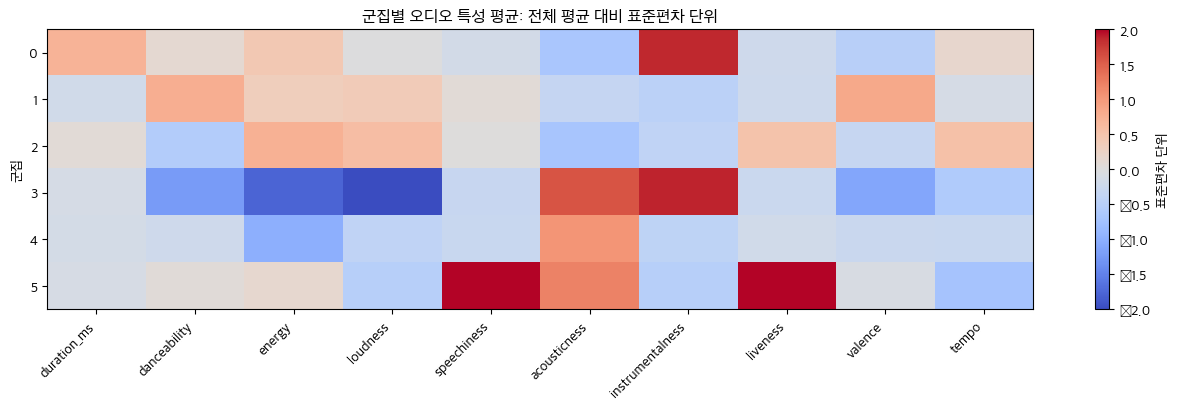

In [213]:
profile_cols = continuous_cols + ["danceability", "energy", "liveness", "valence"]
profile_cols = list(dict.fromkeys(c for c in profile_cols if c in df_final.columns))

cluster_profile = df_final.groupby("cluster")[profile_cols].mean()
cluster_profile.insert(0, "곡 수", df_final.groupby("cluster").size())
if "popularity" in df_final.columns:
    cluster_profile["인기도 중앙값"] = df_final.groupby("cluster")["popularity"].median()
display(cluster_profile.round(3))

# 표준화 특성의 군집별 평균을 색으로 표시해 상대적 특징을 읽습니다.
profile_z = (cluster_profile[continuous_cols] -
             df_final[continuous_cols].mean()) / df_final[continuous_cols].std(ddof=0)
fig, ax = plt.subplots(figsize=(13, max(4, 0.7 * len(profile_z))))
image = ax.imshow(profile_z, aspect="auto", cmap="coolwarm", vmin=-2, vmax=2)
ax.set_yticks(range(len(profile_z.index)))
ax.set_yticklabels([str(x) for x in profile_z.index])
ax.set_xticks(range(len(profile_z.columns)))
ax.set_xticklabels(profile_z.columns, rotation=45, ha="right")
ax.set_title("군집별 오디오 특성 평균: 전체 평균 대비 표준편차 단위")
ax.set_ylabel("군집")
plt.colorbar(image, ax=ax, label="표준편차 단위")
plt.tight_layout()
plt.show()

/var/folders/4v/tf2tg78s6yd4n5__j_8dggcm0000gn/T/ipykernel_54838/2749023649.py:25: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  plt.tight_layout()
/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


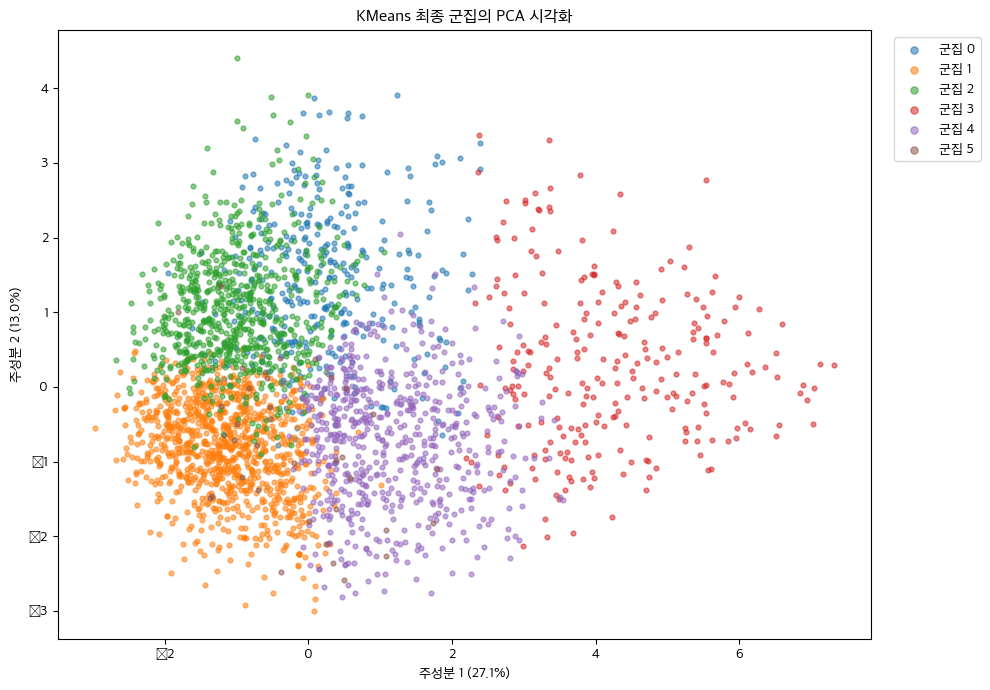

참고: K-Means/GMM은 전체 데이터에 적합했습니다. PCA 그래프만 보기 쉽게 최대 3,000곡을 표시합니다.


In [214]:
# PCA는 시각화를 위한 2차원 투영이며, 군집화 자체는 원래 특성 공간에서 수행했습니다.
viz_n = min(3000, len(df_final))
viz_df = df_final.sample(n=viz_n, random_state=RANDOM_STATE)
viz_X = X.loc[viz_df.index].to_numpy(dtype=np.float32)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
viz_xy = pca.fit_transform(viz_X)
viz_labels = viz_df["cluster"].to_numpy()

fig, ax = plt.subplots(figsize=(10, 7))
for cluster_id in sorted(np.unique(viz_labels)):
    mask = viz_labels == cluster_id
    label = "잡음 (-1)" if cluster_id == -1 else f"군집 {cluster_id}"
    ax.scatter(
        viz_xy[mask, 0],
        viz_xy[mask, 1],
        s=12,
        alpha=0.55,
        label=label,
    )
ax.set_title(f"{FINAL_METHOD} 최종 군집의 PCA 시각화")
ax.set_xlabel(f"주성분 1 ({pca.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"주성분 2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.legend(markerscale=1.5, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

if FINAL_METHOD in ["KMeans", "GMM"]:
    print("참고: K-Means/GMM은 전체 데이터에 적합했습니다. PCA 그래프만 보기 쉽게 최대 3,000곡을 표시합니다.")
else:
    print("참고: DBSCAN/Mean Shift는 비교 표본에서만 적합했으며, 그래프도 해당 표본에서 표시합니다.")

## 다음 단계

1. 이 노트북을 위에서부터 실행하고 비교표를 확인합니다.
2. 지표와 군집 크기, 결과 해석 가능성을 함께 고려해 FINAL_METHOD와 파라미터를 결정합니다.
3. 통계 검정은 최종 군집 결과에 대해 해석 보조자료로 사용합니다. p-value 하나로 최종 모델을 고르지 않습니다.
4. 마지막 셀에서 최종 K-Means의 track_id와 cluster 라벨을 웹에 내보냅니다. 웹은 같은 군집 안에서 코사인 유사도 순으로 추천합니다.

In [ ]:
# 최종 test2 K-Means 라벨을 웹 추천기가 track_id로 연결할 수 있도록 내보냅니다.
if FINAL_METHOD != "KMeans":
    raise ValueError("웹 추천 결과 내보내기는 현재 K-Means 최종 모델만 지원합니다.")
web_data_candidates = [Path("spotify-recommender-web/cluster-data"),
                       Path("project2/spotify-recommender-web/cluster-data")]
web_data_dir = next((path for path in web_data_candidates if path.parent.exists()),
                    web_data_candidates[0])
web_data_dir.mkdir(parents=True, exist_ok=True)
cluster_export = df_final[["track_id", "cluster"]].copy()
cluster_export["track_id"] = cluster_export["track_id"].astype(str)
cluster_export["cluster"] = cluster_export["cluster"].astype(int)
cluster_export_path = web_data_dir / "test2_clusters.csv"
cluster_export.to_csv(cluster_export_path, index=False)
print(f"웹용 test2 군집 라벨 저장: {cluster_export_path} ({len(cluster_export):,}곡)")
display(cluster_export.groupby("cluster").size().rename("웹 내보내기 곡 수").to_frame())